In [ ]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Python executable: /usr/bin/python3


In [ ]:
!python -m pip install --only-binary=tokenizers tokenizers

In [ ]:
!python -m pip install --only-binary=tokenizers tokenizers

In [ ]:
import torch
import transformers
import tokenizers
import datasets
import evaluate
import jiwer

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Datasets:", datasets.__version__)

print("GPU available:", torch.cuda.is_available())

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


PyTorch: 2.11.0+cu130
Transformers: 5.22.0
Tokenizers: 0.23.3
Datasets: 4.8.5
GPU available: True


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02"

folders = [
    "dataset",
    "checkpoints",
    "results",
    "plots",
    "reports"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project folders created successfully.")
print(PROJECT_DIR)

Project folders created successfully.
/content/drive/MyDrive/TrOCR_Assignment_02


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02"

folders = [
    "dataset/raw",
    "checkpoints",
    "results",
    "plots",
    "reports"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project folders created successfully.")
print(PROJECT_DIR)

Project folders created successfully.
/content/drive/MyDrive/TrOCR_Assignment_02


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

In [ ]:
# ==========================================
# STEP 1: IMPORT LIBRARIES AND SETUP PATHS
# ==========================================

import os
import zipfile
import tarfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Define project directories
PROJECT_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02"
RAW_DIR = os.path.join(PROJECT_DIR, "dataset", "raw")
EXTRACT_DIR = "/content/iam_extracted"

# Create required folders automatically
folders = [
    RAW_DIR,
    os.path.join(PROJECT_DIR, "checkpoints"),
    os.path.join(PROJECT_DIR, "results"),
    os.path.join(PROJECT_DIR, "plots"),
    os.path.join(PROJECT_DIR, "reports"),
    EXTRACT_DIR
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

# Verify setup
print("SETUP COMPLETED")
print("Project directory:", PROJECT_DIR)
print("Dataset directory:", RAW_DIR)
print("Dataset folder exists:", os.path.exists(RAW_DIR))
print("Files currently in dataset folder:", os.listdir(RAW_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SETUP COMPLETED
Project directory: /content/drive/MyDrive/TrOCR_Assignment_02
Dataset directory: /content/drive/MyDrive/TrOCR_Assignment_02/dataset/raw
Dataset folder exists: True
Files currently in dataset folder: ['1archive.zip']


In [ ]:
# ==========================================
# STEP 2: CHECK DATASET FILES
# ==========================================

files = os.listdir(RAW_DIR)

if len(files) == 0:
    print("WARNING: No dataset files found!")
    print("Upload your IAM dataset archives into:")
    print(RAW_DIR)
else:
    print("DATASET FILES FOUND:\n")

    for file in files:
        path = os.path.join(RAW_DIR, file)

        if os.path.isfile(path):
            size_gb = os.path.getsize(path) / (1024 ** 3)
            print(f"{file} | {size_gb:.2f} GB")
        else:
            print(f"{file} | Folder")

DATASET FILES FOUND:

1archive.zip | 4.31 GB


In [ ]:
# ==========================================
# STEP 3: INSPECT DATASET ARCHIVES
# ==========================================

for file in os.listdir(RAW_DIR):

    archive_path = os.path.join(RAW_DIR, file)

    print("\nFILE:", file)

    if file.lower().endswith(".zip"):

        with zipfile.ZipFile(archive_path, "r") as archive:
            names = archive.namelist()
            print("Number of files:", len(names))
            print("First 15 entries:")
            print(names[:15])

    elif file.lower().endswith((".tar", ".tar.gz", ".tgz")):

        with tarfile.open(archive_path, "r:*") as archive:
            names = archive.getnames()
            print("Number of files:", len(names))
            print("First 15 entries:")
            print(names[:15])

    else:
        print("Not a ZIP or TAR archive. Skipping.")



FILE: 1archive.zip
Number of files: 1540
First 15 entries:
['__notebook_source__.ipynb', 'data/000/a01-000u.png', 'data/000/a01-003u.png', 'data/000/a01-007u.png', 'data/000/a01-011u.png', 'data/000/a01-014u.png', 'data/000/a01-020u.png', 'data/000/a01-026u.png', 'data/000/a01-030u.png', 'data/000/a01-043u.png', 'data/000/a01-049u.png', 'data/000/a01-049x.png', 'data/000/a01-053u.png', 'data/000/a01-058u.png', 'data/000/a01-063u.png']


In [ ]:
# ==========================================
# STEP 4: DETAILED ZIP INSPECTION
# ==========================================

import zipfile
import os
from collections import Counter

ZIP_PATH = os.path.join(RAW_DIR, "1archive.zip")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    all_files = archive.namelist()

    # Count file extensions
    extensions = Counter(
        os.path.splitext(name)[1].lower()
        for name in all_files
        if not name.endswith("/")
    )

    print("TOTAL ENTRIES:", len(all_files))
    print("\nFILE TYPES:")
    for extension, count in extensions.items():
        print(extension if extension else "[No extension]", ":", count)

    # Find annotation and split files
    print("\nPOSSIBLE ANNOTATION / SPLIT FILES:")

    matches = [
        name for name in all_files
        if name.lower().endswith(
            (".txt", ".csv", ".tsv", ".xml", ".json")
        )
    ]

    if matches:
        for name in matches[:100]:
            print(name)
    else:
        print("No annotation or split files found.")

    # Show all top-level folders
    print("\nTOP-LEVEL CONTENT:")
    top_level = sorted(set(name.split("/")[0] for name in all_files))
    for name in top_level:
        print(name)

    # Show first 30 image filenames
    print("\nSAMPLE IMAGE FILES:")
    image_files = [
        name for name in all_files
        if name.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    for name in image_files[:30]:
        print(name)

TOTAL ENTRIES: 1540

FILE TYPES:
.ipynb : 1
.png : 1539

POSSIBLE ANNOTATION / SPLIT FILES:
No annotation or split files found.

TOP-LEVEL CONTENT:
__notebook_source__.ipynb
data

SAMPLE IMAGE FILES:
data/000/a01-000u.png
data/000/a01-003u.png
data/000/a01-007u.png
data/000/a01-011u.png
data/000/a01-014u.png
data/000/a01-020u.png
data/000/a01-026u.png
data/000/a01-030u.png
data/000/a01-043u.png
data/000/a01-049u.png
data/000/a01-049x.png
data/000/a01-053u.png
data/000/a01-058u.png
data/000/a01-063u.png
data/000/a01-068u.png
data/000/a01-072u.png
data/000/a01-077u.png
data/000/a01-082u.png
data/000/a01-087u.png
data/000/a01-091u.png
data/000/a01-096u.png
data/000/a01-102u.png
data/000/a01-107u.png
data/000/a01-113u.png
data/000/a01-117u.png
data/000/a01-122u.png
data/000/a01-128u.png
data/000/a01-132u.png
data/000/a01-132x.png
data/000/a03-050.png


In [ ]:
# ==========================================
# STEP 5: CHECK EXTRACTION SIZE
# ==========================================

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    total_size = sum(
        item.file_size for item in archive.infolist()
    )

    print("Compressed size:",
          round(os.path.getsize(ZIP_PATH) / (1024**3), 2), "GB")

    print("Uncompressed size:",
          round(total_size / (1024**3), 2), "GB")

    print("Total files:", len(archive.namelist()))

Compressed size: 4.31 GB
Uncompressed size: 4.31 GB
Total files: 1540


In [ ]:
# ==========================================
# STEP 6: READ ORIGINAL NOTEBOOK INFORMATION
# ==========================================

import json
import zipfile
import os

ZIP_PATH = os.path.join(RAW_DIR, "1archive.zip")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    notebook_name = "__notebook_source__.ipynb"

    if notebook_name in archive.namelist():

        notebook_data = archive.read(notebook_name)
        notebook = json.loads(notebook_data.decode("utf-8"))

        print("NOTEBOOK FOUND\n")

        for index, cell in enumerate(notebook.get("cells", [])):

            if cell.get("cell_type") == "markdown":
                source = "".join(cell.get("source", []))
                if source.strip():
                    print(f"\n--- MARKDOWN CELL {index} ---")
                    print(source[:3000])

            elif cell.get("cell_type") == "code":
                source = "".join(cell.get("source", []))
                if source.strip():
                    print(f"\n--- CODE CELL {index} ---")
                    print(source[:2000])

    else:
        print("Notebook not found.")

NOTEBOOK FOUND



In [ ]:
# ==========================================
# STEP 7: IMAGE INSPECTION
# ==========================================

import zipfile
from PIL import Image
from io import BytesIO
from collections import Counter

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    image_names = [
        name for name in archive.namelist()
        if name.lower().endswith(".png")
    ]

    print("Total images:", len(image_names))
    print("\nFIRST 20 FILENAMES:")

    for name in image_names[:20]:
        print(name)

    print("\nIMAGE DIMENSIONS:")

    dimensions = Counter()

    for name in image_names[:50]:
        image_data = archive.read(name)

        with Image.open(BytesIO(image_data)) as img:
            dimensions[img.size] += 1

    for dimension, count in dimensions.items():
        print(dimension, ":", count)

Total images: 1539

FIRST 20 FILENAMES:
data/000/a01-000u.png
data/000/a01-003u.png
data/000/a01-007u.png
data/000/a01-011u.png
data/000/a01-014u.png
data/000/a01-020u.png
data/000/a01-026u.png
data/000/a01-030u.png
data/000/a01-043u.png
data/000/a01-049u.png
data/000/a01-049x.png
data/000/a01-053u.png
data/000/a01-058u.png
data/000/a01-063u.png
data/000/a01-068u.png
data/000/a01-072u.png
data/000/a01-077u.png
data/000/a01-082u.png
data/000/a01-087u.png
data/000/a01-091u.png

IMAGE DIMENSIONS:
(2479, 3542) : 50


In [ ]:
# ==========================================
# STEP 8: CHECK IMAGE NAMING PATTERN
# ==========================================

import re

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    image_names = [
        os.path.basename(name)
        for name in archive.namelist()
        if name.lower().endswith(".png")
    ]

    print("TOTAL IMAGES:", len(image_names))

    print("\nUNIQUE PREFIXES:")

    prefixes = Counter(
        name.split("-")[0]
        for name in image_names
    )

    for prefix, count in prefixes.most_common(20):
        print(prefix, ":", count)

    print("\nSAMPLE FILENAME PATTERNS:")

    for name in image_names[:30]:
        print(name)

TOTAL IMAGES: 1539

UNIQUE PREFIXES:
g06 : 158
a01 : 66
c03 : 60
h07 : 42
f07 : 38
b04 : 32
m04 : 32
c04 : 31
k04 : 31
a02 : 30
g07 : 30
l04 : 30
n04 : 30
e04 : 29
b06 : 28
d06 : 28
r06 : 28
a05 : 27
a06 : 27
g04 : 27

SAMPLE FILENAME PATTERNS:
a01-000u.png
a01-003u.png
a01-007u.png
a01-011u.png
a01-014u.png
a01-020u.png
a01-026u.png
a01-030u.png
a01-043u.png
a01-049u.png
a01-049x.png
a01-053u.png
a01-058u.png
a01-063u.png
a01-068u.png
a01-072u.png
a01-077u.png
a01-082u.png
a01-087u.png
a01-091u.png
a01-096u.png
a01-102u.png
a01-107u.png
a01-113u.png
a01-117u.png
a01-122u.png
a01-128u.png
a01-132u.png
a01-132x.png
a03-050.png


In [ ]:
import os

from google.colab import drive
drive.mount('/content/drive')

RAW_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02/dataset/raw"

print("Checking folder:", RAW_DIR)

if os.path.exists(RAW_DIR):
    print("\nFiles found:")

    for filename in os.listdir(RAW_DIR):
        path = os.path.join(RAW_DIR, filename)

        if os.path.isfile(path):
            size = os.path.getsize(path) / (1024 * 1024)
            print(f"{filename}  |  {size:.2f} MB")
else:
    print("Folder does not exist. Check your Google Drive folder names.")

Mounted at /content/drive
Checking folder: /content/drive/MyDrive/TrOCR_Assignment_02/dataset/raw

Files found:
1archive.zip  |  4411.46 MB
largeWriterIndependentTextLineRecognitionTask.zip  |  0.02 MB
ascii.tar  |  7.44 MB
lines.tar  |  651.79 MB


In [ ]:
import os

RAW_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02/dataset/raw"

required_files = [
    "lines.tar",
    "ascii.tar",
    "largeWriterIndependentTextLineRecognitionTask.zip"
]

for filename in required_files:

    path = os.path.join(RAW_DIR, filename)

    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing: {filename}")

    print(
        filename,
        round(os.path.getsize(path) / (1024**2), 2),
        "MB"
    )

print("\nAll three files are available.")

lines.tar 651.79 MB
ascii.tar 7.44 MB
largeWriterIndependentTextLineRecognitionTask.zip 0.02 MB

All three files are available.


In [ ]:
import os
import tarfile
import zipfile

EXTRACT_DIR = "/content/iam_extracted"
os.makedirs(EXTRACT_DIR, exist_ok=True)

# Extract line images
with tarfile.open(
    os.path.join(RAW_DIR, "lines.tar"), "r:"
) as archive:
    archive.extractall(EXTRACT_DIR)

print("Line images extracted.")

# Extract annotations
with tarfile.open(
    os.path.join(RAW_DIR, "ascii.tar"), "r:"
) as archive:
    archive.extractall(EXTRACT_DIR)

print("Annotations extracted.")

# Extract official splits
with zipfile.ZipFile(
    os.path.join(
        RAW_DIR,
        "largeWriterIndependentTextLineRecognitionTask.zip"
    )
) as archive:
    archive.extractall(EXTRACT_DIR)

print("Official splits extracted.")

/tmp/ipykernel_434/3141106179.py:12: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(EXTRACT_DIR)


Line images extracted.


/tmp/ipykernel_434/3141106179.py:20: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(EXTRACT_DIR)


Annotations extracted.
Official splits extracted.


In [ ]:
from pathlib import Path

all_files = list(Path(EXTRACT_DIR).rglob("*"))

print("Total extracted files:", len(all_files))

print("\nAnnotation files:")

for p in all_files:
    if p.name == "lines.txt":
        print(p)

print("\nSplit files:")

for p in all_files:
    if p.name in [
        "trainset.txt",
        "validationset1.txt",
        "validationset2.txt",
        "testset.txt"
    ]:
        print(p)

print("\nSample PNG images:")

png_files = [
    p for p in all_files
    if p.suffix.lower() == ".png"
]

for p in png_files[:10]:
    print(p)


Total extracted files: 14978

Annotation files:
/content/iam_extracted/lines.txt

Split files:
/content/iam_extracted/largeWriterIndependentTextLineRecognitionTask/validationset2.txt
/content/iam_extracted/largeWriterIndependentTextLineRecognitionTask/testset.txt
/content/iam_extracted/largeWriterIndependentTextLineRecognitionTask/validationset1.txt
/content/iam_extracted/largeWriterIndependentTextLineRecognitionTask/trainset.txt

Sample PNG images:
/content/iam_extracted/m01/m01-012/m01-012-08.png
/content/iam_extracted/m01/m01-012/m01-012-03.png
/content/iam_extracted/m01/m01-012/m01-012-02.png
/content/iam_extracted/m01/m01-012/m01-012-09.png
/content/iam_extracted/m01/m01-012/m01-012-05.png
/content/iam_extracted/m01/m01-012/m01-012-10.png
/content/iam_extracted/m01/m01-012/m01-012-07.png
/content/iam_extracted/m01/m01-012/m01-012-06.png
/content/iam_extracted/m01/m01-012/m01-012-04.png
/content/iam_extracted/m01/m01-012/m01-012-00.png


In [ ]:
from pathlib import Path

all_files = list(Path(EXTRACT_DIR).rglob("*"))

def find_file(filename):
    matches = [
        p for p in all_files
        if p.is_file() and p.name == filename
    ]

    if not matches:
        raise FileNotFoundError(
            f"Could not find {filename} inside {EXTRACT_DIR}"
        )

    return matches[0]


ANNOTATION_FILE = find_file("lines.txt")
TRAIN_FILE = find_file("trainset.txt")
VAL1_FILE = find_file("validationset1.txt")
VAL2_FILE = find_file("validationset2.txt")
TEST_FILE = find_file("testset.txt")

print("Annotations:", ANNOTATION_FILE)
print("Training split:", TRAIN_FILE)
print("Validation 1:", VAL1_FILE)
print("Validation 2:", VAL2_FILE)
print("Testing split:", TEST_FILE)

Annotations: /content/iam_extracted/lines.txt
Training split: /content/iam_extracted/largeWriterIndependentTextLineRecognitionTask/trainset.txt
Validation 1: /content/iam_extracted/largeWriterIndependentTextLineRecognitionTask/validationset1.txt
Validation 2: /content/iam_extracted/largeWriterIndependentTextLineRecognitionTask/validationset2.txt
Testing split: /content/iam_extracted/largeWriterIndependentTextLineRecognitionTask/testset.txt


In [ ]:
import pandas as pd
import os
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import pandas as pd

records = []

with open(ANNOTATION_FILE, "r", encoding="utf-8") as file:

    for line in file:

        line = line.strip()

        if not line or line.startswith("#"):
            continue

        parts = line.split(maxsplit=8)

        if len(parts) != 9:
            continue

        line_id = parts[0]
        status = parts[1]
        transcription = parts[8]

        if status != "ok":
            continue

        if transcription.strip() == "###":
            continue

        text_value = transcription.replace("|", " ").strip()

        if text_value:
            records.append({
                "line_id": line_id,
                "text": text_value
            })

annotations_df = pd.DataFrame(records)

print("Valid annotations:", len(annotations_df))
display(annotations_df.head(10))

Valid annotations: 11344


,line_id,text
0,a01-000u-00,A MOVE to stop Mr. Gaitskell from
1,a01-000u-01,nominating any more Labour life Peers
2,a01-000u-02,is to be made at a meeting of Labour
3,a01-000u-04,put down a resolution on the subject
4,a01-000u-06,"Griffiths , M P for Manchester Exchange ."
5,a01-000x-00,A MOVE to stop Mr. Gaitskell from nominating
6,a01-000x-01,any more Labour life Peers is to be made at a
7,a01-000x-02,meeting of Labour 0M Ps tomorrow . Mr. Michael
8,a01-000x-03,Foot has put down a resolution on the subject
9,a01-000x-04,"and he is to be backed by Mr. Will Griffiths ,"


In [ ]:
from pathlib import Path

image_map = {}

for image_path in Path(EXTRACT_DIR).rglob("*.png"):
    image_map[image_path.stem] = str(image_path)

annotations_df["image_path"] = (
    annotations_df["line_id"].map(image_map)
)

print("Total annotations:", len(annotations_df))
print("Matched images:", annotations_df["image_path"].notna().sum())
print("Missing images:", annotations_df["image_path"].isna().sum())

annotations_df = annotations_df.dropna(
    subset=["image_path"]
).copy()

annotations_df.reset_index(drop=True, inplace=True)

Total annotations: 11344
Matched images: 11344
Missing images: 0


In [ ]:
train_df = annotations_df[
    annotations_df["line_id"].isin(train_ids)
].copy()

val_df = annotations_df[
    annotations_df["line_id"].isin(val_ids)
].copy()

test_df = annotations_df[
    annotations_df["line_id"].isin(test_ids)
].copy()

print("TRAINING SAMPLES:", len(train_df))
print("VALIDATION SAMPLES:", len(val_df))
print("TESTING SAMPLES:", len(test_df))

annotation_ids = set(annotations_df["line_id"])

print("\nMISSING ANNOTATIONS:")
print("Training:", len(train_ids - annotation_ids))
print("Validation:", len(val_ids - annotation_ids))
print("Testing:", len(test_ids - annotation_ids))

TRAINING SAMPLES: 5419
VALIDATION SAMPLES: 1539
TESTING SAMPLES: 1480

MISSING ANNOTATIONS:
Training: 742
Validation: 301
Testing: 381


In [ ]:
import os

os.makedirs(RESULTS_DIR, exist_ok=True)

train_df.to_csv(
    os.path.join(RESULTS_DIR, "train.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(RESULTS_DIR, "validation.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(RESULTS_DIR, "test.csv"),
    index=False
)

print("All three datasets saved successfully!")

All three datasets saved successfully!


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02"

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
PLOTS_DIR = os.path.join(PROJECT_DIR, "plots")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("All project directories are ready.")

All project directories are ready.


In [ ]:
train_df.to_csv(
    os.path.join(RESULTS_DIR, "train.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(RESULTS_DIR, "validation.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(RESULTS_DIR, "test.csv"),
    index=False
)

print("All datasets saved successfully!")

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

All datasets saved successfully!
Training: 5419
Validation: 1539
Testing: 1480


In [ ]:
print("OFFICIAL SPLIT COUNTS")
print("Training IDs:", len(train_ids))
print("Validation IDs:", len(val_ids))
print("Testing IDs:", len(test_ids))

print("\nMATCHED DATA COUNTS")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nMISSING FROM ANNOTATIONS")
annotation_ids = set(annotations_df["line_id"])

print("Training missing:", len(train_ids - annotation_ids))
print("Validation missing:", len(val_ids - annotation_ids))
print("Testing missing:", len(test_ids - annotation_ids))

print("\nMISSING IMAGE FILES")
print("Total available images:", len(image_map))

OFFICIAL SPLIT COUNTS
Training IDs: 6161
Validation IDs: 1840
Testing IDs: 1861

MATCHED DATA COUNTS
Training: 5419
Validation: 1539
Testing: 1480

MISSING FROM ANNOTATIONS
Training missing: 742
Validation missing: 301
Testing missing: 381

MISSING IMAGE FILES
Total available images: 13353


In [ ]:
with open(ANNOTATION_FILE, "r", encoding="utf-8") as file:
    count = 0

    for line in file:
        if line.strip() and not line.startswith("#"):
            print(line.strip())
            count += 1

        if count == 5:
            break

a01-000u-00 ok 154 19 408 746 1661 89 A|MOVE|to|stop|Mr.|Gaitskell|from
a01-000u-01 ok 156 19 395 932 1850 105 nominating|any|more|Labour|life|Peers
a01-000u-02 ok 157 16 408 1106 1986 105 is|to|be|made|at|a|meeting|of|Labour
a01-000u-03 err 156 23 430 1290 1883 70 M Ps|tomorrow|.|Mr.|Michael|Foot|has
a01-000u-04 ok 157 20 395 1474 1830 94 put|down|a|resolution|on|the|subject


In [ ]:
from collections import Counter

status_counts = Counter()
total_lines = 0
valid_format = 0
all_annotation_ids = set()

with open(ANNOTATION_FILE, "r", encoding="utf-8") as file:
    for line in file:
        line = line.strip()

        if not line or line.startswith("#"):
            continue

        total_lines += 1
        parts = line.split(maxsplit=8)

        if len(parts) == 9:
            valid_format += 1
            all_annotation_ids.add(parts[0])
            status_counts[parts[1]] += 1

print("Total annotation records:", total_lines)
print("Records with expected format:", valid_format)
print("Status counts:", status_counts)
print("Unique annotation IDs:", len(all_annotation_ids))

Total annotation records: 13353
Records with expected format: 13353
Status counts: Counter({'ok': 11344, 'err': 2009})
Unique annotation IDs: 13353


In [ ]:
print("Official split IDs:")
print("Training:", len(train_ids))
print("Validation:", len(val_ids))
print("Testing:", len(test_ids))

print("\nIDs not found in annotation file:")
print("Training:", len(set(train_ids) - all_annotation_ids))
print("Validation:", len(set(val_ids) - all_annotation_ids))
print("Testing:", len(set(test_ids) - all_annotation_ids))

print("\nIDs found in annotations but not in official splits:")
all_split_ids = set(train_ids) | set(val_ids) | set(test_ids)
print(len(all_annotation_ids - all_split_ids))

Official split IDs:
Training: 6161
Validation: 1840
Testing: 1861

IDs not found in annotation file:
Training: 0
Validation: 0
Testing: 0

IDs found in annotations but not in official splits:
3491


In [ ]:
from pathlib import Path

image_ids = {
    p.stem for p in Path(EXTRACT_DIR).rglob("*.png")
}

print("Total PNG image IDs:", len(image_ids))

print("\nOfficial split IDs with images:")
print("Training:", len(set(train_ids) & image_ids))
print("Validation:", len(set(val_ids) & image_ids))
print("Testing:", len(set(test_ids) & image_ids))

Total PNG image IDs: 13353

Official split IDs with images:
Training: 6161
Validation: 1840
Testing: 1861


In [ ]:
# Count only records marked "ok" in each official split

ok_ids = set()

with open(ANNOTATION_FILE, "r", encoding="utf-8") as file:
    for line in file:
        line = line.strip()

        if not line or line.startswith("#"):
            continue

        parts = line.split(maxsplit=8)

        if len(parts) == 9 and parts[1] == "ok":
            ok_ids.add(parts[0])

train_ok = set(train_ids) & ok_ids
val_ok = set(val_ids) & ok_ids
test_ok = set(test_ids) & ok_ids

print("USABLE DATASET COUNTS")
print("Training:", len(train_ok))
print("Validation:", len(val_ok))
print("Testing:", len(test_ok))
print("Total:", len(train_ok) + len(val_ok) + len(test_ok))

USABLE DATASET COUNTS
Training: 5419
Validation: 1539
Testing: 1480
Total: 8438


In [ ]:
train_df = annotations_df[
    annotations_df["line_id"].isin(train_ids)
].copy()

val_df = annotations_df[
    annotations_df["line_id"].isin(val_ids)
].copy()

test_df = annotations_df[
    annotations_df["line_id"].isin(test_ids)
].copy()

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 5419
Validation samples: 1539
Testing samples: 1480


In [ ]:
import pandas as pd
from pathlib import Path

# 1. Read annotations and keep only records marked "ok"
records = []

with open(ANNOTATION_FILE, "r", encoding="utf-8") as file:
    for line in file:
        line = line.strip()

        if not line or line.startswith("#"):
            continue

        parts = line.split(maxsplit=8)

        if len(parts) != 9:
            continue

        line_id = parts[0]
        status = parts[1]
        transcription = parts[8]

        if status != "ok":
            continue

        if transcription.strip() == "###":
            continue

        text_value = transcription.replace("|", " ").strip()

        if text_value:
            records.append({
                "line_id": line_id,
                "text": text_value
            })

annotations_df = pd.DataFrame(records)

# 2. Match annotations with image files
image_map = {
    image_path.stem: str(image_path)
    for image_path in Path(EXTRACT_DIR).rglob("*.png")
}

annotations_df["image_path"] = annotations_df["line_id"].map(image_map)

# 3. Remove records without matching images
annotations_df = annotations_df.dropna(subset=["image_path"]).copy()

# 4. Create official splits
train_df = annotations_df[
    annotations_df["line_id"].isin(train_ids)
].copy()

val_df = annotations_df[
    annotations_df["line_id"].isin(val_ids)
].copy()

test_df = annotations_df[
    annotations_df["line_id"].isin(test_ids)
].copy()

# 5. Display results
print("FINAL DATASET COUNTS")
print("--------------------")
print("All usable annotations:", len(annotations_df))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total split samples:", len(train_df) + len(val_df) + len(test_df))

print("\nMissing images:", annotations_df["image_path"].isna().sum())
print("\nSample records:")
display(train_df.head())

FINAL DATASET COUNTS
--------------------
All usable annotations: 11344
Training: 5419
Validation: 1539
Testing: 1480
Total split samples: 8438

Missing images: 0

Sample records:


,line_id,text,image_path
0,a01-000u-00,A MOVE to stop Mr. Gaitskell from,/content/iam_extracted/a01/a01-000u/a01-000u-0...
1,a01-000u-01,nominating any more Labour life Peers,/content/iam_extracted/a01/a01-000u/a01-000u-0...
2,a01-000u-02,is to be made at a meeting of Labour,/content/iam_extracted/a01/a01-000u/a01-000u-0...
3,a01-000u-04,put down a resolution on the subject,/content/iam_extracted/a01/a01-000u/a01-000u-0...
4,a01-000u-06,"Griffiths , M P for Manchester Exchange .",/content/iam_extracted/a01/a01-000u/a01-000u-0...


In [ ]:
# Save final datasets
train_df.to_csv(os.path.join(PROJECT_DIR, "train.csv"), index=False)
val_df.to_csv(os.path.join(PROJECT_DIR, "validation.csv"), index=False)
test_df.to_csv(os.path.join(PROJECT_DIR, "test.csv"), index=False)

print("Dataset CSV files saved successfully!")

print("\nFinal dataset sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Dataset CSV files saved successfully!

Final dataset sizes:
Training: 5419
Validation: 1539
Testing: 1480


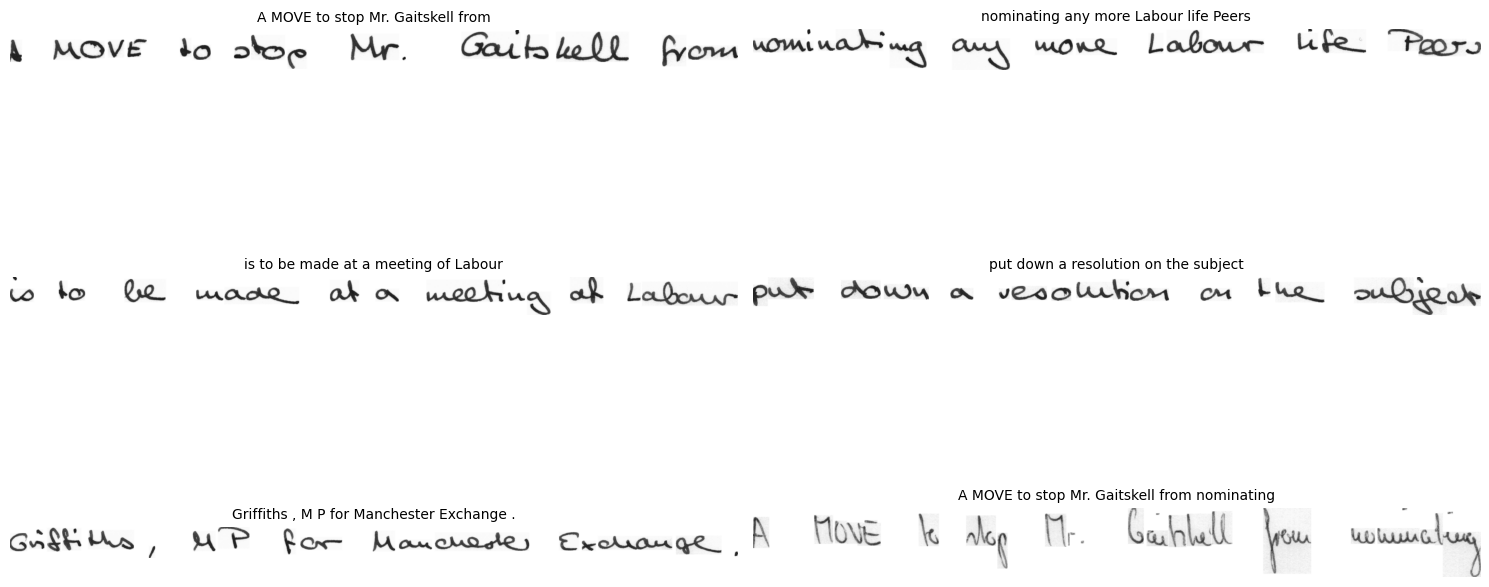

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(3, 2, figsize=(15, 9))

for i, ax in enumerate(axes.flat):
    row = train_df.iloc[i]

    image = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(row["text"], fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

import torch

# Recreate output folders if necessary
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
PLOTS_DIR = os.path.join(PROJECT_DIR, "plots")

for folder in [CHECKPOINT_DIR, RESULTS_DIR, PLOTS_DIR]:
    os.makedirs(folder, exist_ok=True)

# Save datasets
train_df.to_csv(os.path.join(PROJECT_DIR, "train.csv"), index=False)
val_df.to_csv(os.path.join(PROJECT_DIR, "validation.csv"), index=False)
test_df.to_csv(os.path.join(PROJECT_DIR, "test.csv"), index=False)

print("Final CSV files saved.")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Final CSV files saved.
Training: 5419
Validation: 1539
Testing: 1480


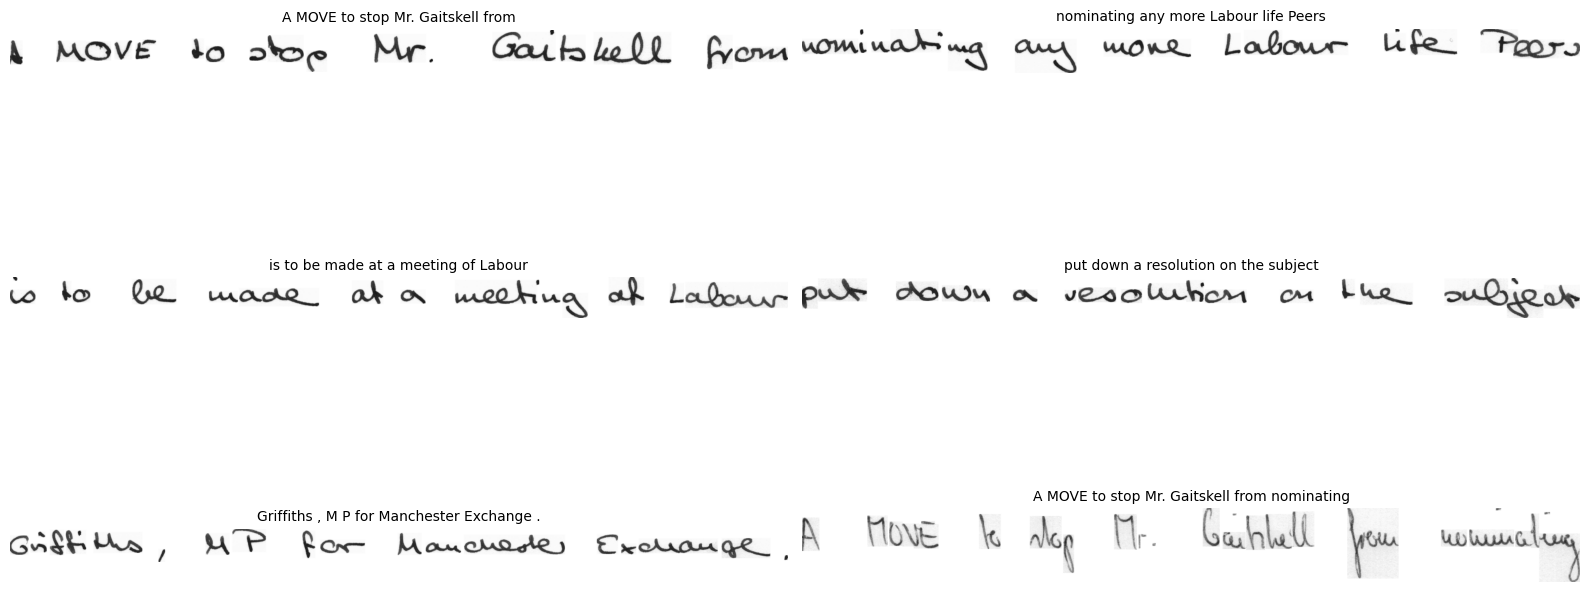

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(16, 9))

for i, ax in enumerate(axes.flat):
    row = train_df.iloc[i]

    image = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(row["text"], fontsize=10)
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(PLOTS_DIR, "dataset_samples.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import sys

print("Python version:", sys.version)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:
import sys
import pip

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Pip version:", pip.__version__)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Python executable: /usr/bin/python3
Pip version: 26.3


In [ ]:
!pip install -q --no-deps \
    requests==2.32.4 \
    fsspec==2025.12.0 \
    numpy==2.3.5

In [ ]:
import torch
import transformers
import tokenizers
import huggingface_hub
import jiwer
import numpy
import pandas
import matplotlib

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("NumPy:", numpy.__version__)

print("GPU available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
Transformers: 4.48.3
Tokenizers: 0.21.0
Hugging Face Hub: 0.36.2
NumPy: 2.3.5
GPU available: True


In [ ]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

MODEL_NAME = "microsoft/trocr-small-stage1"

processor = TrOCRProcessor.from_pretrained(MODEL_NAME)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_NAME)

print("TrOCR loaded successfully!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/276 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.48, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json:   0%|          | 0.00/327 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors:   0%|          | 0.00/246M [00:00<?, ?B/s]

Config of the encoder: <class 'transformers.models.deit.modeling_deit.DeiTModel'> is overwritten by shared encoder config: DeiTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 384,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 1536,
  "layer_norm_eps": 1e-12,
  "model_type": "deit",
  "num_attention_heads": 6,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": true,
  "transformers_version": "4.48.3"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "relu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 384,
  "d_model": 256,
  "decoder_attention_heads": 8,
  "decoder_ffn_dim": 1024,
  "decode

generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

TrOCR loaded successfully!


In [ ]:
import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

MODEL_NAME = "microsoft/trocr-small-stage1"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

processor = TrOCRProcessor.from_pretrained(MODEL_NAME)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_NAME)

# Keep the checkpoint's existing token configuration
model.config.use_cache = False
model.config.decoder.use_cache = False

# Move model to GPU
model.to(device)

print("Model:", MODEL_NAME)
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Model loaded and ready!")
print("Image size:", processor.image_processor.size)
print("Tokenizer vocabulary:", processor.tokenizer.vocab_size)

Config of the encoder: <class 'transformers.models.deit.modeling_deit.DeiTModel'> is overwritten by shared encoder config: DeiTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 384,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 1536,
  "layer_norm_eps": 1e-12,
  "model_type": "deit",
  "num_attention_heads": 6,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": true,
  "transformers_version": "4.48.3"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "relu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 384,
  "d_model": 256,
  "decoder_attention_heads": 8,
  "decoder_ffn_dim": 1024,
  "decode

Model: microsoft/trocr-small-stage1
Device: cuda
GPU: Tesla T4
Model loaded and ready!
Image size: {'height': 384, 'width': 384}
Tokenizer vocabulary: 64002


In [ ]:
import os
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02"

train_df = pd.read_csv(os.path.join(PROJECT_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(PROJECT_DIR, "validation.csv"))
test_df = pd.read_csv(os.path.join(PROJECT_DIR, "test.csv"))

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining data preview:")
display(train_df.head())

print("\nMissing image paths:")
print("Train:", (~train_df["image_path"].apply(os.path.exists)).sum())
print("Validation:", (~val_df["image_path"].apply(os.path.exists)).sum())
print("Test:", (~test_df["image_path"].apply(os.path.exists)).sum())

Training samples: 5419
Validation samples: 1539
Testing samples: 1480

Training data preview:


,line_id,text,image_path
0,a01-000u-00,A MOVE to stop Mr. Gaitskell from,/content/iam_extracted/a01/a01-000u/a01-000u-0...
1,a01-000u-01,nominating any more Labour life Peers,/content/iam_extracted/a01/a01-000u/a01-000u-0...
2,a01-000u-02,is to be made at a meeting of Labour,/content/iam_extracted/a01/a01-000u/a01-000u-0...
3,a01-000u-04,put down a resolution on the subject,/content/iam_extracted/a01/a01-000u/a01-000u-0...
4,a01-000u-06,"Griffiths , M P for Manchester Exchange .",/content/iam_extracted/a01/a01-000u/a01-000u-0...



Missing image paths:
Train: 0
Validation: 0
Test: 0


In [ ]:
from torch.utils.data import Dataset
from PIL import Image
import torch

MAX_TARGET_LENGTH = 128

class IAMDataset(Dataset):
    def __init__(self, dataframe, processor):
        self.dataframe = dataframe.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        # Load handwriting image
        image = Image.open(row["image_path"]).convert("RGB")

        # Convert image into model input
        pixel_values = self.processor(
            images=image,
            return_tensors="pt"
        ).pixel_values.squeeze(0)

        # Convert transcription into token IDs
        labels = self.processor.tokenizer(
            row["text"],
            padding="max_length",
            max_length=MAX_TARGET_LENGTH,
            truncation=True,
            return_tensors="pt"
        ).input_ids.squeeze(0)

        # Ignore padding tokens during loss calculation
        labels[labels == self.processor.tokenizer.pad_token_id] = -100

        return {
            "pixel_values": pixel_values,
            "labels": labels
        }


# Create datasets
train_dataset = IAMDataset(train_df, processor)
val_dataset = IAMDataset(val_df, processor)
test_dataset = IAMDataset(test_df, processor)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

print("\nDataset preparation successful!")

Training dataset: 5419
Validation dataset: 1539
Testing dataset: 1480

Dataset preparation successful!


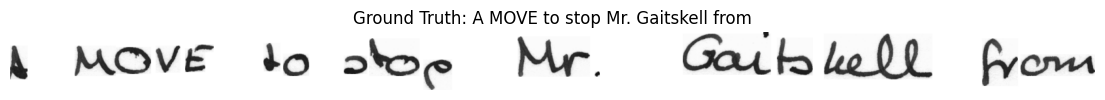

Image tensor shape: torch.Size([3, 384, 384])
Label tensor shape: torch.Size([128])
Image tensor type: torch.float32
Label tensor type: torch.int64


In [ ]:
import matplotlib.pyplot as plt

sample = train_df.iloc[0]

image = Image.open(sample["image_path"]).convert("RGB")

plt.figure(figsize=(14, 4))
plt.imshow(image, cmap="gray")
plt.title("Ground Truth: " + sample["text"])
plt.axis("off")
plt.show()

# Check the processed sample
processed_sample = train_dataset[0]

print("Image tensor shape:", processed_sample["pixel_values"].shape)
print("Label tensor shape:", processed_sample["labels"].shape)
print("Image tensor type:", processed_sample["pixel_values"].dtype)
print("Label tensor type:", processed_sample["labels"].dtype)

In [ ]:
token_lengths = train_df["text"].apply(
    lambda text: len(processor.tokenizer(text).input_ids)
)

print("Longest transcription:", token_lengths.max())
print("Average token length:", round(token_lengths.mean(), 2))
print("Samples exceeding 128 tokens:", (token_lengths > 128).sum())

Longest transcription: 23
Average token length: 11.47
Samples exceeding 128 tokens: 0


In [ ]:
!pip install -q jiwer

In [ ]:
import jiwer
import numpy as np
from tqdm.auto import tqdm

def predict_dataframe(dataframe, model, processor, batch_size=4):
    model.eval()
    predictions = []
    device = next(model.parameters()).device

    with torch.no_grad():
        for start in tqdm(range(0, len(dataframe), batch_size)):
            batch_df = dataframe.iloc[start:start + batch_size]

            images = [
                Image.open(path).convert("RGB")
                for path in batch_df["image_path"]
            ]

            pixel_values = processor(
                images=images,
                return_tensors="pt"
            ).pixel_values.to(device)

            generated_ids = model.generate(
                pixel_values,
                max_new_tokens=MAX_TARGET_LENGTH,
                num_beams=1
            )

            batch_predictions = processor.batch_decode(
                generated_ids,
                skip_special_tokens=True
            )

            predictions.extend(batch_predictions)

    return predictions


def calculate_metrics(references, predictions):
    return {
        "CER": jiwer.cer(references, predictions),
        "WER": jiwer.wer(references, predictions)
    }

print("Baseline evaluation functions ready!")

Baseline evaluation functions ready!


In [ ]:
small_val_df = val_df.head(10).copy()

baseline_sample_predictions = predict_dataframe(
    small_val_df,
    model,
    processor,
    batch_size=2
)

for i in range(10):
    print("Actual:    ", small_val_df.iloc[i]["text"])
    print("Predicted: ", baseline_sample_predictions[i])
    print("-" * 70)

  0%|          | 0/5 [00:00<?, ?it/s]

Actual:     assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
Predicted:  assurances "Bello Bella Horne" (Raslophine), a lively song that damages lumpo mid-any.
----------------------------------------------------------------------
Actual:     CHRIS CHARLES , 39 , who lives in Stockton-on-Tees , is an accountant .
Predicted:  CHRIS CHARLES, 85, who lives in Stockton - on - Tees, is on a coouulant.
----------------------------------------------------------------------
Actual:     He is also a director of a couple of garages . And he finds time as well to be a lyric
Predicted:  He is also a director of a couple of garages. And he finds time as well to be a lyrics
----------------------------------------------------------------------
Actual:     writer . He writes with Tolchard Evans , composer of " Lady of Spain " and other big hits .
Predicted:  writer. We strikes with Tolchard Elows, computer op "Lady or Spain" and alter big hits.
-----------

In [ ]:
import jiwer
import pandas as pd
import torch
import os

def predict_dataframe(dataframe, model, processor, batch_size=2):
    model.eval()
    predictions = []
    device = next(model.parameters()).device

    with torch.no_grad():
        for start in range(0, len(dataframe), batch_size):

            batch_df = dataframe.iloc[start:start + batch_size]

            images = [
                Image.open(path).convert("RGB")
                for path in batch_df["image_path"]
            ]

            pixel_values = processor(
                images=images,
                return_tensors="pt"
            ).pixel_values.to(device)

            generated_ids = model.generate(
                pixel_values,
                max_new_tokens=128,
                num_beams=1
            )

            predictions.extend(
                processor.batch_decode(
                    generated_ids,
                    skip_special_tokens=True
                )
            )

    return predictions


# Generate predictions for validation data
baseline_predictions = predict_dataframe(
    val_df,
    model,
    processor,
    batch_size=2
)

# Actual and predicted text
actual_texts = val_df["text"].tolist()

# Calculate metrics
baseline_cer = jiwer.cer(actual_texts, baseline_predictions)
baseline_wer = jiwer.wer(actual_texts, baseline_predictions)

print("BASELINE VALIDATION RESULTS")
print("---------------------------")
print(f"CER: {baseline_cer:.4f} ({baseline_cer * 100:.2f}%)")
print(f"WER: {baseline_wer:.4f} ({baseline_wer * 100:.2f}%)")

# Save baseline results
baseline_results = {
    "model": MODEL_NAME,
    "dataset": "Validation",
    "CER": baseline_cer,
    "WER": baseline_wer
}

os.makedirs(RESULTS_DIR, exist_ok=True)

pd.DataFrame([baseline_results]).to_csv(
    os.path.join(RESULTS_DIR, "baseline_results.csv"),
    index=False
)

print("\nBaseline results saved successfully!")

BASELINE VALIDATION RESULTS
---------------------------
CER: 0.1320 (13.20%)
WER: 0.3524 (35.24%)


NameError: name 'RESULTS_DIR' is not defined

In [ ]:
import os
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(RESULTS_DIR, exist_ok=True)

baseline_results = {
    "model": MODEL_NAME,
    "dataset": "Validation",
    "CER": baseline_cer,
    "WER": baseline_wer
}

pd.DataFrame([baseline_results]).to_csv(
    os.path.join(RESULTS_DIR, "baseline_results.csv"),
    index=False
)

print("Baseline results saved successfully!")

Baseline results saved successfully!


In [ ]:
import os
import json
import torch
import jiwer
import numpy as np

from transformers import (
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments
)

# Project folders
PROJECT_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02"

CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

OUTPUT_DIR = os.path.join(CHECKPOINT_DIR, "trocr_training")
FINAL_MODEL_DIR = os.path.join(CHECKPOINT_DIR, "trocr_final")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Training configuration
EPOCHS = 3
BATCH_SIZE = 2
GRADIENT_ACCUMULATION = 4
LEARNING_RATE = 5e-5

# Metrics calculation
def compute_metrics(pred):
    pred_ids = pred.predictions

    if isinstance(pred_ids, tuple):
        pred_ids = pred_ids[0]

    label_ids = pred.label_ids.copy()
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id

    predicted_text = processor.batch_decode(
        pred_ids,
        skip_special_tokens=True
    )

    actual_text = processor.batch_decode(
        label_ids,
        skip_special_tokens=True
    )

    return {
        "cer": jiwer.cer(actual_text, predicted_text),
        "wer": jiwer.wer(actual_text, predicted_text)
    }


# Training arguments
training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,

    num_train_epochs=EPOCHS,

    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,

    gradient_accumulation_steps=GRADIENT_ACCUMULATION,

    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    optim="adamw_torch",

    evaluation_strategy="epoch",
    save_strategy="epoch",

    logging_strategy="steps",
    logging_steps=100,

    predict_with_generate=True,
    generation_max_length=MAX_TARGET_LENGTH,
    generation_num_beams=1,

    load_best_model_at_end=True,
    metric_for_best_model="cer",
    greater_is_better=False,

    fp16=torch.cuda.is_available(),

    save_total_limit=2,
    remove_unused_columns=False,

    report_to="none",
    seed=42,
    dataloader_num_workers=0
)

print("Training configuration ready!")
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION)
print("Learning rate:", LEARNING_RATE)
print("GPU:", torch.cuda.get_device_name(0))

Training configuration ready!
Epochs: 3
Batch size: 2
Gradient accumulation: 4
Learning rate: 5e-05
GPU: Tesla T4


/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1575: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [ ]:
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    processing_class=processor,

    compute_metrics=compute_metrics
)

print("TrOCR Trainer initialized successfully!")

TrOCR Trainer initialized successfully!


In [ ]:
print("Starting TrOCR fine-tuning...")

train_result = trainer.train()

print("\nTraining completed successfully!")

# Save final best model
trainer.save_model(FINAL_MODEL_DIR)
processor.save_pretrained(FINAL_MODEL_DIR)

# Save training state
trainer.save_state()

# Save training history
with open(
    os.path.join(RESULTS_DIR, "training_history.json"),
    "w"
) as f:
    json.dump(trainer.state.log_history, f, indent=4)

print("\nBest model saved at:", FINAL_MODEL_DIR)
print("Training history saved successfully!")

Starting TrOCR fine-tuning...


TypeError: DeiTModel.forward() got an unexpected keyword argument 'num_items_in_batch'

In [ ]:
import inspect

# Check whether Trainer supports disabling this argument
print(inspect.signature(training_args.__class__))

(output_dir: str, overwrite_output_dir: bool = False, do_train: bool = False, do_eval: bool = False, do_predict: bool = False, eval_strategy: Union[transformers.trainer_utils.IntervalStrategy, str] = 'no', prediction_loss_only: bool = False, per_device_train_batch_size: int = 8, per_device_eval_batch_size: int = 8, per_gpu_train_batch_size: Optional[int] = None, per_gpu_eval_batch_size: Optional[int] = None, gradient_accumulation_steps: int = 1, eval_accumulation_steps: Optional[int] = None, eval_delay: Optional[float] = 0, torch_empty_cache_steps: Optional[int] = None, learning_rate: float = 5e-05, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, max_grad_norm: float = 1.0, num_train_epochs: float = 3.0, max_steps: int = -1, lr_scheduler_type: Union[transformers.trainer_utils.SchedulerType, str] = 'linear', lr_scheduler_kwargs: Union[dict, str, NoneType] = <factory>, warmup_ratio: float = 0.0, warmup_steps: int = 0, log_level:

In [ ]:
# Disable the new Trainer loss argument
training_args.average_tokens_across_devices = False

# Reinitialize Trainer
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=processor,
    compute_metrics=compute_metrics
)

# Patch Trainer's input preparation to remove the unsupported argument
original_prepare_inputs = trainer._prepare_inputs

def patched_prepare_inputs(inputs):
    inputs.pop("num_items_in_batch", None)
    return original_prepare_inputs(inputs)

trainer._prepare_inputs = patched_prepare_inputs

print("Trainer compatibility fix applied successfully!")

Trainer compatibility fix applied successfully!


In [ ]:
print("Starting TrOCR fine-tuning...")

train_result = trainer.train()

print("\nTraining completed successfully!")

trainer.save_model(FINAL_MODEL_DIR)
processor.save_pretrained(FINAL_MODEL_DIR)
trainer.save_state()

with open(
    os.path.join(RESULTS_DIR, "training_history.json"),
    "w"
) as f:
    json.dump(trainer.state.log_history, f, indent=4)

print("\nBest model saved at:", FINAL_MODEL_DIR)
print("Training history saved successfully!")

Starting TrOCR fine-tuning...


TypeError: DeiTModel.forward() got an unexpected keyword argument 'num_items_in_batch'

In [ ]:
# Prevent Trainer from passing num_items_in_batch
# into the TrOCR model's forward method.

trainer.model_accepts_loss_kwargs = False

print("Model accepts loss kwargs:", trainer.model_accepts_loss_kwargs)
print("Compatibility fix applied!")

Model accepts loss kwargs: False
Compatibility fix applied!


In [ ]:
print("Starting TrOCR fine-tuning...")

train_result = trainer.train()

print("\nTraining completed successfully!")

# Save best model
trainer.save_model(FINAL_MODEL_DIR)
processor.save_pretrained(FINAL_MODEL_DIR)
trainer.save_state()

# Save training history
with open(
    os.path.join(RESULTS_DIR, "training_history.json"),
    "w"
) as f:
    json.dump(trainer.state.log_history, f, indent=4)

print("\nBest model saved at:", FINAL_MODEL_DIR)
print("Training history saved successfully!")

Starting TrOCR fine-tuning...


ValueError: Make sure to set the decoder_start_token_id attribute of the model's configuration.

In [ ]:
# Set the special token IDs required by TrOCR

model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
model.config.eos_token_id = processor.tokenizer.sep_token_id

# Keep decoder configuration consistent
model.config.decoder.pad_token_id = processor.tokenizer.pad_token_id
model.config.decoder.eos_token_id = processor.tokenizer.sep_token_id

# Update generation configuration too
model.generation_config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.generation_config.pad_token_id = processor.tokenizer.pad_token_id
model.generation_config.eos_token_id = processor.tokenizer.sep_token_id

print("Decoder configuration fixed!")
print("Decoder start token:", model.config.decoder_start_token_id)
print("Padding token:", model.config.pad_token_id)
print("End token:", model.config.eos_token_id)

Decoder configuration fixed!
Decoder start token: 0
Padding token: 1
End token: 2


In [ ]:
import os, re, tarfile, zipfile, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from collections import Counter

import torch
from google.colab import drive

drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02"
RAW_DIR = os.path.join(PROJECT_DIR, "dataset", "raw")
EXTRACT_DIR = "/content/iam_extracted"

CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
PLOTS_DIR = os.path.join(PROJECT_DIR, "plots")

for folder in [RAW_DIR, EXTRACT_DIR, CHECKPOINT_DIR,
               RESULTS_DIR, PLOTS_DIR]:
    os.makedirs(folder, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

Mounted at /content/drive
Device: cuda
GPU: Tesla T4


In [ ]:
train_df = pd.read_csv(os.path.join(PROJECT_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(PROJECT_DIR, "validation.csv"))
test_df = pd.read_csv(os.path.join(PROJECT_DIR, "test.csv"))

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 5419
Validation samples: 1539
Testing samples: 1480


In [ ]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from torch.utils.data import Dataset

MODEL_NAME = "microsoft/trocr-small-stage1"
MAX_TARGET_LENGTH = 128

processor = TrOCRProcessor.from_pretrained(MODEL_NAME)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_NAME)

model.config.use_cache = False
model.config.decoder.use_cache = False

# Configure special token IDs
model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
model.config.eos_token_id = processor.tokenizer.sep_token_id

model.config.decoder.pad_token_id = processor.tokenizer.pad_token_id
model.config.decoder.eos_token_id = processor.tokenizer.sep_token_id

model.generation_config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.generation_config.pad_token_id = processor.tokenizer.pad_token_id
model.generation_config.eos_token_id = processor.tokenizer.sep_token_id

model.to(device)

class IAMDataset(Dataset):
    def __init__(self, dataframe, processor):
        self.dataframe = dataframe.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")

        pixel_values = self.processor(
            images=image, return_tensors="pt"
        ).pixel_values.squeeze(0)

        labels = self.processor.tokenizer(
            row["text"],
            padding="max_length",
            max_length=MAX_TARGET_LENGTH,
            truncation=True,
            return_tensors="pt"
        ).input_ids.squeeze(0)

        labels[labels == self.processor.tokenizer.pad_token_id] = -100

        return {
            "pixel_values": pixel_values,
            "labels": labels
        }

train_dataset = IAMDataset(train_df, processor)
val_dataset = IAMDataset(val_df, processor)
test_dataset = IAMDataset(test_df, processor)

print("Model and datasets restored successfully!")
print("Device:", device)

preprocessor_config.json:   0%|          | 0.00/276 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/327 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 1.36MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  246MB            

generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

model.safetensors: downloading bytes:           |  0.00B            

Model and datasets restored successfully!
Device: cuda


In [ ]:
!pip install -q jiwer

In [ ]:
import jiwer
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments

OUTPUT_DIR = os.path.join(CHECKPOINT_DIR, "trocr_training")
FINAL_MODEL_DIR = os.path.join(CHECKPOINT_DIR, "trocr_final")

EPOCHS = 3
BATCH_SIZE = 2
GRADIENT_ACCUMULATION = 4
LEARNING_RATE = 5e-5

def compute_metrics(pred):
    pred_ids = pred.predictions

    if isinstance(pred_ids, tuple):
        pred_ids = pred_ids[0]

    label_ids = pred.label_ids.copy()
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id

    predicted_text = processor.batch_decode(
        pred_ids, skip_special_tokens=True
    )

    actual_text = processor.batch_decode(
        label_ids, skip_special_tokens=True
    )

    return {
        "cer": jiwer.cer(actual_text, predicted_text),
        "wer": jiwer.wer(actual_text, predicted_text)
    }

training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    optim="adamw_torch",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    predict_with_generate=True,
    generation_max_length=MAX_TARGET_LENGTH,
    generation_num_beams=1,
    load_best_model_at_end=True,
    metric_for_best_model="cer",
    greater_is_better=False,
    fp16=torch.cuda.is_available(),
    save_total_limit=2,
    remove_unused_columns=False,
    report_to="none",
    seed=42,
    dataloader_num_workers=0
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=processor,
    compute_metrics=compute_metrics
)

# Compatibility workaround for the earlier num_items_in_batch error
trainer.model_accepts_loss_kwargs = False

print("Trainer recreated successfully!")

Trainer recreated successfully!


In [ ]:
print("Starting TrOCR fine-tuning...")

train_result = trainer.train()

print("\nTraining completed successfully!")

# Save best model
trainer.save_model(FINAL_MODEL_DIR)
processor.save_pretrained(FINAL_MODEL_DIR)
trainer.save_state()

# Save training history
with open(
    os.path.join(RESULTS_DIR, "training_history.json"),
    "w"
) as f:
    json.dump(trainer.state.log_history, f, indent=4)

print("\nBest model saved at:", FINAL_MODEL_DIR)
print("Training history saved successfully!")

Starting TrOCR fine-tuning...


Epoch,Training Loss,Validation Loss


OverflowError: number too small to fit in target type

In [ ]:
import os

RAW_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02/dataset/raw"

for filename in [
    "lines.tar",
    "ascii.tar",
    "largeWriterIndependentTextLineRecognitionTask.zip"
]:
    path = os.path.join(RAW_DIR, filename)
    print(filename, "FOUND" if os.path.exists(path) else "MISSING")

lines.tar FOUND
ascii.tar FOUND
largeWriterIndependentTextLineRecognitionTask.zip FOUND


In [ ]:
import os
import tarfile
import zipfile

EXTRACT_DIR = "/content/iam_extracted"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with tarfile.open(os.path.join(RAW_DIR, "lines.tar"), "r:") as archive:
    archive.extractall(EXTRACT_DIR)

with tarfile.open(os.path.join(RAW_DIR, "ascii.tar"), "r:") as archive:
    archive.extractall(EXTRACT_DIR)

with zipfile.ZipFile(
    os.path.join(RAW_DIR, "largeWriterIndependentTextLineRecognitionTask.zip")
) as archive:
    archive.extractall(EXTRACT_DIR)

print("Dataset extraction completed!")

/tmp/ipykernel_411/2957468897.py:9: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(EXTRACT_DIR)
/tmp/ipykernel_411/2957468897.py:12: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(EXTRACT_DIR)


Dataset extraction completed!


In [ ]:
from pathlib import Path

image_map = {
    p.stem: str(p)
    for p in Path(EXTRACT_DIR).rglob("*.png")
}

print("Total extracted PNG images:", len(image_map))

for df_name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    df["image_path"] = df["line_id"].map(image_map)

    missing = df["image_path"].isna().sum()

    print(f"{df_name}: {len(df)} samples")
    print(f"{df_name} missing images: {missing}")

Total extracted PNG images: 13353
Training: 5419 samples
Training missing images: 0
Validation: 1539 samples
Validation missing images: 0
Testing: 1480 samples
Testing missing images: 0


In [ ]:
test_image = "/content/iam_extracted/b04/b04-128/b04-128-01.png"

matches = list(Path(EXTRACT_DIR).rglob("b04-128-01.png"))

print("Matching image:", matches)

Matching image: [PosixPath('/content/iam_extracted/b04/b04-128/b04-128-01.png')]


In [ ]:
import os

print("Global training step:", trainer.state.global_step)
print("Current epoch:", trainer.state.epoch)

print("\nSaved checkpoints:")

if os.path.exists(OUTPUT_DIR):
    checkpoints = [
        folder for folder in os.listdir(OUTPUT_DIR)
        if folder.startswith("checkpoint-")
    ]
    print(checkpoints if checkpoints else "No checkpoints found")
else:
    print("Training output directory not found")

Global training step: 678
Current epoch: 1.0

Saved checkpoints:
No checkpoints found


In [ ]:
def compute_metrics(pred):
    pred_ids = pred.predictions

    if isinstance(pred_ids, tuple):
        pred_ids = pred_ids[0]

    pred_ids = np.asarray(pred_ids).copy()

    # Handle logits if predictions are not token IDs
    if pred_ids.ndim == 3:
        pred_ids = np.argmax(pred_ids, axis=-1)

    # Replace invalid/padding IDs before decoding
    pred_ids[pred_ids < 0] = processor.tokenizer.pad_token_id
    pred_ids = pred_ids.astype(np.int64)

    label_ids = pred.label_ids.copy()
    label_ids[label_ids < 0] = processor.tokenizer.pad_token_id
    label_ids = label_ids.astype(np.int64)

    predicted_text = processor.batch_decode(
        pred_ids, skip_special_tokens=True
    )

    actual_text = processor.batch_decode(
        label_ids, skip_special_tokens=True
    )

    return {
        "cer": jiwer.cer(actual_text, predicted_text),
        "wer": jiwer.wer(actual_text, predicted_text)
    }

trainer.compute_metrics = compute_metrics

print("Metric calculation updated successfully!")

Metric calculation updated successfully!


In [ ]:
print("Model available:", model is not None)
print("Trainer available:", trainer is not None)
print("GPU available:", torch.cuda.is_available())
print("Current training step:", trainer.state.global_step)

print("Model device:", next(model.parameters()).device)

Model available: True
Trainer available: True
GPU available: True
Current training step: 678
Model device: cuda:0


In [ ]:
print("Current metric function:", trainer.compute_metrics.__name__)
print("Training step:", trainer.state.global_step)
print("Model device:", next(trainer.model.parameters()).device)

Current metric function: compute_metrics
Training step: 678
Model device: cuda:0


In [ ]:
import os
import torch

RECOVERY_DIR = os.path.join(
    CHECKPOINT_DIR, "recovery_after_epoch1_partial"
)

os.makedirs(RECOVERY_DIR, exist_ok=True)

torch.save(
    trainer.model.state_dict(),
    os.path.join(RECOVERY_DIR, "model_weights.pt")
)

processor.save_pretrained(RECOVERY_DIR)

print("Recovery model weights saved successfully!")
print("Location:", RECOVERY_DIR)

Recovery model weights saved successfully!
Location: /content/drive/MyDrive/TrOCR_Assignment_02/checkpoints/recovery_after_epoch1_partial


In [ ]:
print("Global step:", trainer.state.global_step)
print("Epoch:", trainer.state.epoch)
print("Training epochs configured:", trainer.args.num_train_epochs)

Global step: 678
Epoch: 1.0
Training epochs configured: 3


In [ ]:
print("Optimizer available:", trainer.optimizer is not None)
print("Scheduler available:", trainer.lr_scheduler is not None)

print("Checkpoint method available:",
      hasattr(trainer, "_save_checkpoint"))

print("Current global step:", trainer.state.global_step)

Optimizer available: True
Scheduler available: True
Checkpoint method available: True
Current global step: 678


In [ ]:
import os

print("Saving full recovery checkpoint...")

trainer._save_checkpoint(trainer.model, trial=None)

RECOVERY_CHECKPOINT = os.path.join(
    OUTPUT_DIR,
    f"checkpoint-{trainer.state.global_step}"
)

print("\nCheckpoint location:", RECOVERY_CHECKPOINT)
print("\nSaved files:")

for file in sorted(os.listdir(RECOVERY_CHECKPOINT)):
    print(file)

Saving full recovery checkpoint...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Checkpoint location: /content/drive/MyDrive/TrOCR_Assignment_02/checkpoints/trocr_training/checkpoint-678

Saved files:
config.json
generation_config.json
model.safetensors
optimizer.pt
processor_config.json
rng_state.pth
scaler.pt
scheduler.pt
tokenizer.json
tokenizer_config.json
trainer_state.json
training_args.bin


In [ ]:
print("Resuming TrOCR training from step 678...")

train_result = trainer.train(
    resume_from_checkpoint=RECOVERY_CHECKPOINT
)

print("\nTraining completed successfully!")
print("Final global step:", trainer.state.global_step)
print("Final epoch:", trainer.state.epoch)

Resuming TrOCR training from step 678...


[transformers] There were missing keys in the checkpoint model loaded: ['encoder.layers.0.attention.q_proj.weight', 'encoder.layers.0.attention.q_proj.bias', 'encoder.layers.0.attention.k_proj.weight', 'encoder.layers.0.attention.k_proj.bias', 'encoder.layers.0.attention.v_proj.weight', 'encoder.layers.0.attention.v_proj.bias', 'encoder.layers.0.attention.o_proj.weight', 'encoder.layers.0.attention.o_proj.bias', 'encoder.layers.0.layernorm_before.weight', 'encoder.layers.0.layernorm_before.bias', 'encoder.layers.0.layernorm_after.weight', 'encoder.layers.0.layernorm_after.bias', 'encoder.layers.0.mlp.fc1.weight', 'encoder.layers.0.mlp.fc1.bias', 'encoder.layers.0.mlp.fc2.weight', 'encoder.layers.0.mlp.fc2.bias', 'encoder.layers.1.attention.q_proj.weight', 'encoder.layers.1.attention.q_proj.bias', 'encoder.layers.1.attention.k_proj.weight', 'encoder.layers.1.attention.k_proj.bias', 'encoder.layers.1.attention.v_proj.weight', 'encoder.layers.1.attention.v_proj.bias', 'encoder.layers.1.at

Epoch,Training Loss,Validation Loss


Epoch,Training Loss,Validation Loss,Cer,Wer
2,0.546399,0.825784,0.787511,0.822115
3,0.345396,0.726042,0.815249,0.842825


Epoch,Training Loss,Validation Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.layers.0.attention.q_proj.weight', 'encoder.layers.0.attention.q_proj.bias', 'encoder.layers.0.attention.k_proj.weight', 'encoder.layers.0.attention.k_proj.bias', 'encoder.layers.0.attention.v_proj.weight', 'encoder.layers.0.attention.v_proj.bias', 'encoder.layers.0.attention.o_proj.weight', 'encoder.layers.0.attention.o_proj.bias', 'encoder.layers.0.layernorm_before.weight', 'encoder.layers.0.layernorm_before.bias', 'encoder.layers.0.layernorm_after.weight', 'encoder.layers.0.layernorm_after.bias', 'encoder.layers.0.mlp.fc1.weight', 'encoder.layers.0.mlp.fc1.bias', 'encoder.layers.0.mlp.fc2.weight', 'encoder.layers.0.mlp.fc2.bias', 'encoder.layers.1.attention.q_proj.weight', 'encoder.layers.1.attention.q_proj.bias', 'encoder.layers.1.attention.k_proj.weight', 'encoder.layers.1.attention.k_proj.bias', 'encoder.layers.1.attention.v_proj.weight', 'encoder.layers.1.attention.v_proj.bias', 'encoder.layers.1.at


Training completed successfully!
Final global step: 2034
Final epoch: 3.0


In [ ]:
import os
import pandas as pd

print("BEST CHECKPOINT:", trainer.state.best_model_checkpoint)
print("BEST VALIDATION CER:", trainer.state.best_metric)
print("FINAL GLOBAL STEP:", trainer.state.global_step)
print("FINAL EPOCH:", trainer.state.epoch)

print("\nMODEL CLASS:", type(trainer.model).__name__)
print("ENCODER CLASS:", type(trainer.model.encoder).__name__)

print("\nFINAL MODEL DIRECTORY EXISTS:",
      os.path.exists(FINAL_MODEL_DIR))

if os.path.exists(FINAL_MODEL_DIR):
    print("FINAL MODEL FILES:")
    for f in sorted(os.listdir(FINAL_MODEL_DIR)):
        print("-", f)

# Inspect five validation samples
trainer.model.eval()
device = next(trainer.model.parameters()).device

sample_df = val_df.head(5).reset_index(drop=True)

images = [
    Image.open(path).convert("RGB")
    for path in sample_df["image_path"]
]

pixel_values = processor(
    images=images,
    return_tensors="pt"
).pixel_values.to(device)

with torch.no_grad():
    generated_ids = trainer.model.generate(
        pixel_values,
        max_new_tokens=128,
        num_beams=1
    )

predictions = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True
)

comparison = pd.DataFrame({
    "Actual Text": sample_df["text"].tolist(),
    "Predicted Text": predictions
})

display(comparison)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


BEST CHECKPOINT: /content/drive/MyDrive/TrOCR_Assignment_02/checkpoints/trocr_training/checkpoint-1356
BEST VALIDATION CER: 0.7875105509794219
FINAL GLOBAL STEP: 2034
FINAL EPOCH: 3.0

MODEL CLASS: VisionEncoderDecoderModel
ENCODER CLASS: DeiTModel

FINAL MODEL DIRECTORY EXISTS: False


,Actual Text,Predicted Text
0,"assuredness "" Bella Bella Marie "" ( Parlophone...",
1,"CHRIS CHARLES , 39 , who lives in Stockton-on-...",
2,He is also a director of a couple of garages ....,He is a director or grunges and one well to a ...
3,"writer . He writes with Tolchard Evans , compo...",
4,"Tolch , as he is known in Tin Pan Alley , like...",


In [ ]:
print("=== MODEL CONFIGURATION ===")
print("Decoder start token:", trainer.model.config.decoder_start_token_id)
print("EOS token:", trainer.model.config.eos_token_id)
print("PAD token:", trainer.model.config.pad_token_id)

print("\n=== GENERATION CONFIGURATION ===")
print(trainer.model.generation_config)

print("\n=== TOKENIZER CONFIGURATION ===")
print("Tokenizer BOS:", processor.tokenizer.bos_token_id)
print("Tokenizer EOS:", processor.tokenizer.eos_token_id)
print("Tokenizer CLS:", processor.tokenizer.cls_token_id)
print("Tokenizer SEP:", processor.tokenizer.sep_token_id)
print("Tokenizer PAD:", processor.tokenizer.pad_token_id)

print("\n=== RAW GENERATED TOKEN IDS ===")
print(generated_ids[:5].cpu().tolist())

print("\n=== PREDICTED TEXT ===")
for i, prediction in enumerate(predictions):
    print(f"Sample {i+1}: {repr(prediction)}")

print("\n=== BEST CHECKPOINT CONTENTS ===")
import os

best_dir = trainer.state.best_model_checkpoint
print("Checkpoint:", best_dir)

if best_dir and os.path.exists(best_dir):
    print(os.listdir(best_dir))

=== MODEL CONFIGURATION ===
Decoder start token: 0
EOS token: 2
PAD token: 1

=== GENERATION CONFIGURATION ===
GenerationConfig {
  "assistant_confidence_threshold": 0.4,
  "assistant_lookbehind": 10,
  "bos_token_id": 0,
  "decoder_start_token_id": 0,
  "diversity_penalty": 0.0,
  "do_sample": false,
  "early_stopping": false,
  "encoder_no_repeat_ngram_size": 0,
  "encoder_repetition_penalty": 1.0,
  "eos_token_id": 2,
  "epsilon_cutoff": 0.0,
  "eta_cutoff": 0.0,
  "length_penalty": 1.0,
  "max_length": 20,
  "min_length": 0,
  "no_repeat_ngram_size": 0,
  "num_assistant_tokens": 20,
  "num_assistant_tokens_schedule": "constant",
  "num_beam_groups": 1,
  "num_beams": 1,
  "num_return_sequences": 1,
  "output_scores": false,
  "pad_token_id": 1,
  "remove_invalid_values": false,
  "repetition_penalty": 1.0,
  "return_dict_in_generate": false,
  "target_lookbehind": 10,
  "temperature": 1.0,
  "top_k": 50,
  "top_p": 1.0,
  "typical_p": 1.0,
  "use_cache": false
}


=== TOKENIZER CON

In [ ]:
import os
import torch
from PIL import Image

RECOVERY_WEIGHTS = os.path.join(
    CHECKPOINT_DIR,
    "recovery_after_epoch1_partial",
    "model_weights.pt"
)

print("Recovery weights exist:", os.path.exists(RECOVERY_WEIGHTS))

# Load the saved weights
saved_weights = torch.load(
    RECOVERY_WEIGHTS,
    map_location="cpu",
    weights_only=True
)

# Restore them into the current model
load_result = trainer.model.load_state_dict(
    saved_weights,
    strict=True
)

print("Weights restored successfully!")
print("Load result:", load_result)

# Test five validation samples
trainer.model.eval()

sample_df = val_df.head(5).reset_index(drop=True)

images = [
    Image.open(path).convert("RGB")
    for path in sample_df["image_path"]
]

pixel_values = processor(
    images=images,
    return_tensors="pt"
).pixel_values.to(device)

with torch.no_grad():
    test_ids = trainer.model.generate(
        pixel_values,
        max_new_tokens=64,
        num_beams=1
    )

test_predictions = processor.batch_decode(
    test_ids,
    skip_special_tokens=True
)

for i in range(5):
    print("\nSample", i + 1)
    print("Actual:   ", sample_df.iloc[i]["text"])
    print("Predicted:", repr(test_predictions[i]))

Recovery weights exist: True
Weights restored successfully!
Load result: <All keys matched successfully>


[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Sample 1
Actual:    assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
Predicted: ''

Sample 2
Actual:    CHRIS CHARLES , 39 , who lives in Stockton-on-Tees , is an accountant .
Predicted: ''

Sample 3
Actual:    He is also a director of a couple of garages . And he finds time as well to be a lyric
Predicted: ''

Sample 4
Actual:    writer . He writes with Tolchard Evans , composer of " Lady of Spain " and other big hits .
Predicted: ''

Sample 5
Actual:    Tolch , as he is known in Tin Pan Alley , likes songs with a month in the title . He wrote
Predicted: ''


In [ ]:
from transformers import VisionEncoderDecoderModel
import torch
from PIL import Image

print("Loading original pretrained TrOCR model...")

baseline_model = VisionEncoderDecoderModel.from_pretrained(
    MODEL_NAME
).to(device)

# Configure token IDs
baseline_model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
baseline_model.config.pad_token_id = processor.tokenizer.pad_token_id
baseline_model.config.eos_token_id = processor.tokenizer.sep_token_id

baseline_model.generation_config.decoder_start_token_id = processor.tokenizer.cls_token_id
baseline_model.generation_config.pad_token_id = processor.tokenizer.pad_token_id
baseline_model.generation_config.eos_token_id = processor.tokenizer.sep_token_id

# Avoid the conflicting max_length warning
baseline_model.generation_config.max_length = 128

baseline_model.eval()

print("\nTesting five validation samples...")

with torch.no_grad():
    baseline_ids = baseline_model.generate(
        pixel_values,
        max_new_tokens=64,
        num_beams=1
    )

baseline_predictions = processor.batch_decode(
    baseline_ids,
    skip_special_tokens=True
)

for i in range(5):
    print("\nSample", i + 1)
    print("Actual:   ", sample_df.iloc[i]["text"])
    print("Original: ", repr(baseline_predictions[i]))
    print("Fine-tuned:", repr(test_predictions[i]))

Loading original pretrained TrOCR model...


Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-stage1
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Both `max_new_tokens` (=64) and `max_length`(=128) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Testing five validation samples...

Sample 1
Actual:    assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
Original:  '. "Bell.'
Fine-tuned: ''

Sample 2
Actual:    CHRIS CHARLES , 39 , who lives in Stockton-on-Tees , is an accountant .
Original:  '.'
Fine-tuned: ''

Sample 3
Actual:    He is also a director of a couple of garages . And he finds time as well to be a lyric
Original:  '"'
Fine-tuned: ''

Sample 4
Actual:    writer . He writes with Tolchard Evans , composer of " Lady of Spain " and other big hits .
Original:  '.'
Fine-tuned: ''

Sample 5
Actual:    Tolch , as he is known in Tin Pan Alley , likes songs with a month in the title . He wrote
Original:  '.'
Fine-tuned: ''


In [ ]:
print("===== TOKENIZER CONFIGURATION =====")
print("BOS token:", processor.tokenizer.bos_token,
      processor.tokenizer.bos_token_id)
print("EOS token:", processor.tokenizer.eos_token,
      processor.tokenizer.eos_token_id)
print("CLS token:", processor.tokenizer.cls_token,
      processor.tokenizer.cls_token_id)
print("SEP token:", processor.tokenizer.sep_token,
      processor.tokenizer.sep_token_id)
print("PAD token:", processor.tokenizer.pad_token,
      processor.tokenizer.pad_token_id)

print("\n===== ORIGINAL MODEL CONFIGURATION =====")
print("Decoder start:", baseline_model.config.decoder_start_token_id)
print("EOS:", baseline_model.config.eos_token_id)
print("PAD:", baseline_model.config.pad_token_id)

print("\n===== GENERATION CONFIGURATION =====")
print(baseline_model.generation_config)

print("\n===== DECODER CONFIGURATION =====")
print("Decoder start:", baseline_model.config.decoder.decoder_start_token_id)
print("EOS:", baseline_model.config.decoder.eos_token_id)
print("PAD:", baseline_model.config.decoder.pad_token_id)

print("\n===== GENERATED TOKEN IDS =====")
print(baseline_ids[0].tolist())

print("\n===== CURRENT IMAGE TENSOR =====")
print("Shape:", pixel_values.shape)
print("Minimum:", pixel_values.min().item())
print("Maximum:", pixel_values.max().item())
print("Mean:", pixel_values.mean().item())

===== TOKENIZER CONFIGURATION =====
BOS token: <s> 0
EOS token: </s> 2
CLS token: <s> 0
SEP token: </s> 2
PAD token: <pad> 1

===== ORIGINAL MODEL CONFIGURATION =====
Decoder start: 0
EOS: 2
PAD: 1

===== GENERATION CONFIGURATION =====
GenerationConfig {
  "bos_token_id": 0,
  "decoder_start_token_id": 0,
  "eos_token_id": 2,
  "max_length": 128,
  "pad_token_id": 1,
  "use_cache": false
}


===== DECODER CONFIGURATION =====
Decoder start: 2
EOS: 2
PAD: 1

===== GENERATED TOKEN IDS =====
[0, 5, 30, 42729, 5, 2]

===== CURRENT IMAGE TENSOR =====
Shape: torch.Size([5, 3, 384, 384])
Minimum: -0.843137264251709
Maximum: 1.0
Mean: 0.8135278820991516


In [ ]:
# Correct decoder start token for TrOCR
CORRECT_START_TOKEN = processor.tokenizer.eos_token_id

for current_model in [baseline_model, trainer.model]:

    current_model.config.decoder_start_token_id = CORRECT_START_TOKEN
    current_model.generation_config.decoder_start_token_id = CORRECT_START_TOKEN

    current_model.config.decoder.decoder_start_token_id = CORRECT_START_TOKEN

    current_model.eval()

print("Corrected decoder start token:", CORRECT_START_TOKEN)

# Test original pretrained model
with torch.no_grad():
    original_ids = baseline_model.generate(
        pixel_values,
        max_new_tokens=64,
        num_beams=1
    )

# Test recovery model
with torch.no_grad():
    recovery_ids = trainer.model.generate(
        pixel_values,
        max_new_tokens=64,
        num_beams=1
    )

original_text = processor.batch_decode(
    original_ids, skip_special_tokens=True
)

recovery_text = processor.batch_decode(
    recovery_ids, skip_special_tokens=True
)

for i in range(5):
    print("\nSample", i + 1)
    print("Actual:   ", sample_df.iloc[i]["text"])
    print("Original: ", repr(original_text[i]))
    print("Recovery: ", repr(recovery_text[i]))

print("\nOriginal generated IDs:", original_ids[0].tolist())
print("Recovery generated IDs:", recovery_ids[0].tolist())

[transformers] Both `max_new_tokens` (=64) and `max_length`(=128) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Corrected decoder start token: 2


[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Sample 1
Actual:    assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
Original:  'assurances "Bello Bella Horne" (Raslophine), a lively song that damages lumpo mid-any.'
Recovery:  ''

Sample 2
Actual:    CHRIS CHARLES , 39 , who lives in Stockton-on-Tees , is an accountant .
Original:  'CHRIS CHARLES, 85, who lives in Stockton - on - Tees, is on a coouulant.'
Recovery:  ''

Sample 3
Actual:    He is also a director of a couple of garages . And he finds time as well to be a lyric
Original:  'He is also a director of a couple of garages. And he finds time as well to be a lyrics'
Recovery:  ''

Sample 4
Actual:    writer . He writes with Tolchard Evans , composer of " Lady of Spain " and other big hits .
Original:  'writer. We strikes with Tolchard Elows, computer op "Lady or Spain" and alter big hits.'
Recovery:  ''

Sample 5
Actual:    Tolch , as he is known in Tin Pan Alley , likes songs with a month in the title . He wrote
Original:  'bleh

In [ ]:
from transformers import VisionEncoderDecoderModel

print("Loading a fresh pretrained model...")

fresh_model = VisionEncoderDecoderModel.from_pretrained(
    MODEL_NAME
).to(device)

# Correct TrOCR configuration
start_id = processor.tokenizer.eos_token_id
pad_id = processor.tokenizer.pad_token_id
eos_id = processor.tokenizer.eos_token_id

fresh_model.config.decoder_start_token_id = start_id
fresh_model.config.pad_token_id = pad_id
fresh_model.config.eos_token_id = eos_id

fresh_model.config.decoder.decoder_start_token_id = start_id
fresh_model.config.decoder.pad_token_id = pad_id
fresh_model.config.decoder.eos_token_id = eos_id

fresh_model.generation_config.decoder_start_token_id = start_id
fresh_model.generation_config.pad_token_id = pad_id
fresh_model.generation_config.eos_token_id = eos_id

fresh_model.config.use_cache = False
fresh_model.config.decoder.use_cache = False

fresh_model.eval()

print("\nConfiguration verification:")
print("Model start token:", fresh_model.config.decoder_start_token_id)
print("Decoder start token:", fresh_model.config.decoder.decoder_start_token_id)
print("Generation start token:", fresh_model.generation_config.decoder_start_token_id)

print("\nTesting fresh model...")

with torch.no_grad():
    fresh_ids = fresh_model.generate(
        pixel_values,
        max_length=65,
        num_beams=1
    )

fresh_predictions = processor.batch_decode(
    fresh_ids,
    skip_special_tokens=True
)

for i in range(5):
    print("\nSample", i + 1)
    print("Actual: ", sample_df.iloc[i]["text"])
    print("Fresh:  ", repr(fresh_predictions[i]))

Loading a fresh pretrained model...


Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-stage1
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Configuration verification:
Model start token: 2
Decoder start token: 2
Generation start token: 2

Testing fresh model...

Sample 1
Actual:  assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
Fresh:   'assurances "Bello Bella Horne" (Raslophine), a lively song that damages lumpo mid-any.'

Sample 2
Actual:  CHRIS CHARLES , 39 , who lives in Stockton-on-Tees , is an accountant .
Fresh:   'CHRIS CHARLES, 85, who lives in Stockton - on - Tees, is on a coouulant.'

Sample 3
Actual:  He is also a director of a couple of garages . And he finds time as well to be a lyric
Fresh:   'He is also a director of a couple of garages. And he finds time as well to be a lyrics'

Sample 4
Actual:  writer . He writes with Tolchard Evans , composer of " Lady of Spain " and other big hits .
Fresh:   'writer. We strikes with Tolchard Elows, computer op "Lady or Spain" and alter big hits.'

Sample 5
Actual:  Tolch , as he is known in Tin Pan Alley , likes songs with

In [ ]:
import os
import json
import torch
import numpy as np
import jiwer

from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments

# Use a NEW folder to preserve previous checkpoints
NEW_OUTPUT_DIR = os.path.join(
    CHECKPOINT_DIR,
    "trocr_training_corrected"
)

os.makedirs(NEW_OUTPUT_DIR, exist_ok=True)

# Ensure the fresh model has the correct configuration
fresh_model.config.decoder_start_token_id = 2
fresh_model.config.pad_token_id = 1
fresh_model.config.eos_token_id = 2

fresh_model.config.decoder.decoder_start_token_id = 2
fresh_model.config.decoder.pad_token_id = 1
fresh_model.config.decoder.eos_token_id = 2

fresh_model.generation_config.decoder_start_token_id = 2
fresh_model.generation_config.pad_token_id = 1
fresh_model.generation_config.eos_token_id = 2
fresh_model.generation_config.max_length = 128

fresh_model.config.use_cache = False
fresh_model.config.decoder.use_cache = False

# Corrected metrics function
def compute_metrics(pred):
    pred_ids = pred.predictions

    if isinstance(pred_ids, tuple):
        pred_ids = pred_ids[0]

    pred_ids = np.asarray(pred_ids).copy()

    if pred_ids.ndim == 3:
        pred_ids = np.argmax(pred_ids, axis=-1)

    pred_ids[pred_ids < 0] = processor.tokenizer.pad_token_id
    pred_ids = pred_ids.astype(np.int64)

    label_ids = pred.label_ids.copy()
    label_ids[label_ids < 0] = processor.tokenizer.pad_token_id
    label_ids = label_ids.astype(np.int64)

    predicted_text = processor.batch_decode(
        pred_ids, skip_special_tokens=True
    )

    actual_text = processor.batch_decode(
        label_ids, skip_special_tokens=True
    )

    return {
        "cer": jiwer.cer(actual_text, predicted_text),
        "wer": jiwer.wer(actual_text, predicted_text)
    }

# Training arguments
training_args_corrected = Seq2SeqTrainingArguments(
    output_dir=NEW_OUTPUT_DIR,

    num_train_epochs=3,

    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,

    gradient_accumulation_steps=4,

    learning_rate=5e-5,
    weight_decay=0.01,
    optim="adamw_torch",

    eval_strategy="epoch",
    save_strategy="epoch",

    logging_strategy="steps",
    logging_steps=100,

    predict_with_generate=True,
    generation_max_length=128,
    generation_num_beams=1,

    load_best_model_at_end=True,
    metric_for_best_model="cer",
    greater_is_better=False,

    fp16=torch.cuda.is_available(),

    save_total_limit=2,
    remove_unused_columns=False,
    report_to="none",
    seed=42,
    dataloader_num_workers=0
)

# Create a completely new Trainer
corrected_trainer = Seq2SeqTrainer(
    model=fresh_model,
    args=training_args_corrected,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=processor,
    compute_metrics=compute_metrics
)

corrected_trainer.model_accepts_loss_kwargs = False

print("Corrected Trainer created successfully!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Output directory:", NEW_OUTPUT_DIR)
print("Decoder start token:",
      corrected_trainer.model.config.decoder_start_token_id)
print("GPU available:", torch.cuda.is_available())

Corrected Trainer created successfully!
Training samples: 5419
Validation samples: 1539
Output directory: /content/drive/MyDrive/TrOCR_Assignment_02/checkpoints/trocr_training_corrected
Decoder start token: 2
GPU available: True


In [ ]:
print("Trainer type:", type(trainer).__name__)

print(
    "Using fresh model:",
    trainer.model is fresh_model
)

print(
    "Correct output directory:",
    trainer.args.output_dir
)

print(
    "Training samples:",
    len(trainer.train_dataset)
)

print(
    "Validation samples:",
    len(trainer.eval_dataset)
)

print(
    "Decoder start token:",
    trainer.model.config.decoder_start_token_id
)

print(
    "Training epochs:",
    trainer.args.num_train_epochs
)

print(
    "Learning rate:",
    trainer.args.learning_rate
)

print(
    "GPU available:",
    torch.cuda.is_available()
)

Trainer type: Seq2SeqTrainer
Using fresh model: False
Correct output directory: /content/drive/MyDrive/TrOCR_Assignment_02/checkpoints/trocr_training
Training samples: 5419
Validation samples: 1539
Decoder start token: 2
Training epochs: 3
Learning rate: 5e-05
GPU available: True


In [ ]:
trainer_corrected = Seq2SeqTrainer(
    model=fresh_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=processor,
    compute_metrics=compute_metrics
)

# Disable unsupported loss-kwargs handling
trainer_corrected.model_accepts_loss_kwargs = False

# Verify
print("Using fresh model:",
      trainer_corrected.model is fresh_model)

print("Output directory:",
      trainer_corrected.args.output_dir)

print("Training samples:",
      len(trainer_corrected.train_dataset))

print("Validation samples:",
      len(trainer_corrected.eval_dataset))

print("Decoder start token:",
      trainer_corrected.model.config.decoder_start_token_id)

print("Corrected Trainer created successfully!")

Using fresh model: True
Output directory: /content/drive/MyDrive/TrOCR_Assignment_02/checkpoints/trocr_training
Training samples: 5419
Validation samples: 1539
Decoder start token: 2
Corrected Trainer created successfully!


In [ ]:
NEW_OUTPUT_DIR = os.path.join(
    CHECKPOINT_DIR,
    "trocr_training_corrected"
)

os.makedirs(NEW_OUTPUT_DIR, exist_ok=True)

trainer_corrected.args.output_dir = NEW_OUTPUT_DIR

print("Verified output directory:",
      trainer_corrected.args.output_dir)

print("Using fresh model:",
      trainer_corrected.model is fresh_model)

Verified output directory: /content/drive/MyDrive/TrOCR_Assignment_02/checkpoints/trocr_training_corrected
Using fresh model: True


In [ ]:
print("Starting corrected TrOCR fine-tuning...")

train_result_corrected = trainer_corrected.train()

print("\nCorrected training completed!")
print("Training results:")
print(train_result_corrected.metrics)

Starting corrected TrOCR fine-tuning...


Epoch,Training Loss,Validation Loss,Cer,Wer
1,0.684786,0.733502,0.108682,0.205178
2,0.329150,0.612219,0.088250,0.171524
3,0.151962,0.525088,0.070728,0.144601


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.layers.0.attention.q_proj.weight', 'encoder.layers.0.attention.q_proj.bias', 'encoder.layers.0.attention.k_proj.weight', 'encoder.layers.0.attention.k_proj.bias', 'encoder.layers.0.attention.v_proj.weight', 'encoder.layers.0.attention.v_proj.bias', 'encoder.layers.0.attention.o_proj.weight', 'encoder.layers.0.attention.o_proj.bias', 'encoder.layers.0.layernorm_before.weight', 'encoder.layers.0.layernorm_before.bias', 'encoder.layers.0.layernorm_after.weight', 'encoder.layers.0.layernorm_after.bias', 'encoder.layers.0.mlp.fc1.weight', 'encoder.layers.0.mlp.fc1.bias', 'encoder.layers.0.mlp.fc2.weight', 'encoder.layers.0.mlp.fc2.bias', 'encoder.layers.1.attention.q_proj.weight', 'encoder.layers.1.attention.q_proj.bias', 'encoder.layers.1.attention.k_proj.weight', 'encoder.layers.1.attention.k_proj.bias', 'encoder.layers.1.attention.v_proj.weight', 'encoder.layers.1.attention.v_proj.bias', 'encoder.layers.1.at


Corrected training completed!
Training results:
{'train_runtime': 1405.4218, 'train_samples_per_second': 11.567, 'train_steps_per_second': 1.447, 'total_flos': 1.9447385433770557e+18, 'train_loss': 0.5026937672756648, 'epoch': 3.0}


In [ ]:
print("Best checkpoint:", trainer_corrected.state.best_model_checkpoint)

print("Best validation CER:",
      trainer_corrected.state.best_metric)

print("Completed epochs:",
      trainer_corrected.state.epoch)

print("Current model class:",
      type(trainer_corrected.model).__name__)

print("Final output directory:",
      trainer_corrected.args.output_dir)

Best checkpoint: /content/drive/MyDrive/TrOCR_Assignment_02/checkpoints/trocr_training_corrected/checkpoint-2034
Best validation CER: 0.07072794481473936
Completed epochs: 3.0
Current model class: VisionEncoderDecoderModel
Final output directory: /content/drive/MyDrive/TrOCR_Assignment_02/checkpoints/trocr_training_corrected


In [ ]:
import os
from safetensors.torch import load_file

BEST_CHECKPOINT = trainer_corrected.state.best_model_checkpoint
WEIGHTS_FILE = os.path.join(BEST_CHECKPOINT, "model.safetensors")

print("Checkpoint exists:", os.path.exists(WEIGHTS_FILE))

# Compare saved checkpoint parameter names with model parameter names
saved_state = load_file(WEIGHTS_FILE, device="cpu")
current_state = trainer_corrected.model.state_dict()

saved_keys = set(saved_state.keys())
current_keys = set(current_state.keys())

matched_keys = saved_keys.intersection(current_keys)
missing_keys = current_keys - saved_keys
unexpected_keys = saved_keys - current_keys

print("\n===== CHECKPOINT WEIGHT DIAGNOSTICS =====")
print("Saved parameter tensors:", len(saved_keys))
print("Current model tensors:", len(current_keys))
print("Matching parameter tensors:", len(matched_keys))
print("Missing parameter tensors:", len(missing_keys))
print("Unexpected parameter tensors:", len(unexpected_keys))

print("\nExample missing keys:")
for key in list(sorted(missing_keys))[:10]:
    print(key)

print("\nExample unexpected keys:")
for key in list(sorted(unexpected_keys))[:10]:
    print(key)

Checkpoint exists: True

===== CHECKPOINT WEIGHT DIAGNOSTICS =====
Saved parameter tensors: 362
Current model tensors: 362
Matching parameter tensors: 170
Missing parameter tensors: 192
Unexpected parameter tensors: 192

Example missing keys:
encoder.layers.0.attention.k_proj.bias
encoder.layers.0.attention.k_proj.weight
encoder.layers.0.attention.o_proj.bias
encoder.layers.0.attention.o_proj.weight
encoder.layers.0.attention.q_proj.bias
encoder.layers.0.attention.q_proj.weight
encoder.layers.0.attention.v_proj.bias
encoder.layers.0.attention.v_proj.weight
encoder.layers.0.layernorm_after.bias
encoder.layers.0.layernorm_after.weight

Example unexpected keys:
encoder.encoder.layer.0.attention.attention.key.bias
encoder.encoder.layer.0.attention.attention.key.weight
encoder.encoder.layer.0.attention.attention.query.bias
encoder.encoder.layer.0.attention.attention.query.weight
encoder.encoder.layer.0.attention.attention.value.bias
encoder.encoder.layer.0.attention.attention.value.weight
e

In [ ]:
import json
import os

# Read the saved checkpoint configuration
config_path = os.path.join(BEST_CHECKPOINT, "config.json")

with open(config_path, "r") as f:
    checkpoint_config = json.load(f)

print("===== CURRENT MODEL =====")
print("Encoder class:", type(trainer_corrected.model.encoder).__name__)
print("Encoder module:", type(trainer_corrected.model.encoder).__module__)
print("Encoder model type:", trainer_corrected.model.encoder.config.model_type)
print("Encoder architectures:", trainer_corrected.model.encoder.config.architectures)

print("\n===== SAVED CHECKPOINT CONFIG =====")
print("Model architecture:", checkpoint_config.get("architectures"))
print("Encoder configuration:")
print(json.dumps(checkpoint_config.get("encoder", {}), indent=2)[:3000])

print("\n===== CURRENT ENCODER KEYS =====")
for key in sorted(current_keys):
    if key.startswith("encoder."):
        print(key)
        if key.startswith("encoder.layers.1."):
            break

print("\n===== SAVED ENCODER KEYS =====")
for key in sorted(saved_keys):
    if key.startswith("encoder."):
        print(key)
        if key.startswith("encoder.encoder.layer.1."):
            break

===== CURRENT MODEL =====
Encoder class: DeiTModel
Encoder module: transformers.models.deit.modeling_deit
Encoder model type: deit
Encoder architectures: None

===== SAVED CHECKPOINT CONFIG =====
Model architecture: ['VisionEncoderDecoderModel']
Encoder configuration:
{
  "add_cross_attention": false,
  "attention_probs_dropout_prob": 0.0,
  "bos_token_id": null,
  "cross_attention_hidden_size": null,
  "decoder_start_token_id": null,
  "dtype": "float32",
  "encoder_stride": 16,
  "eos_token_id": null,
  "finetuning_task": null,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 384,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 1536,
  "is_decoder": false,
  "layer_norm_eps": 1e-12,
  "model_type": "deit",
  "num_attention_heads": 6,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "pad_token_id": null,
  "patch_size": 16,
  "pooler_act": "tanh",
  "pooler_output_size": 384,
  "prefix": null,
  "pruned_heads": {},
  "qkv_bias": true,
  

In [ ]:
import re
import torch

def convert_deit_key(key):
    # Convert old DeiT layer naming to current naming
    key = key.replace(
        "encoder.encoder.layer.",
        "encoder.layers."
    )

    replacements = {
        ".attention.attention.query.": ".attention.q_proj.",
        ".attention.attention.key.": ".attention.k_proj.",
        ".attention.attention.value.": ".attention.v_proj.",
        ".attention.output.dense.": ".attention.o_proj.",
        ".intermediate.dense.": ".mlp.fc1.",
        ".output.dense.": ".mlp.fc2.",
    }

    for old, new in replacements.items():
        key = key.replace(old, new)

    return key


converted_state = {
    convert_deit_key(key): value
    for key, value in saved_state.items()
}

shape_matches = []
shape_mismatches = []
unmatched_keys = []

for key, saved_tensor in converted_state.items():

    if key not in current_state:
        unmatched_keys.append(key)

    elif saved_tensor.shape != current_state[key].shape:
        shape_mismatches.append(
            (key, saved_tensor.shape, current_state[key].shape)
        )

    else:
        shape_matches.append(key)


print("===== CONVERTED CHECKPOINT DIAGNOSTICS =====")
print("Converted checkpoint tensors:", len(converted_state))
print("Matching tensor shapes:", len(shape_matches))
print("Shape mismatches:", len(shape_mismatches))
print("Unmatched converted keys:", len(unmatched_keys))


# Compare actual tensor values for matching keys
if len(shape_matches) > 0:

    differences = []

    for key in shape_matches:
        saved_tensor = converted_state[key].float()
        current_tensor = current_state[key].detach().cpu().float()

        max_difference = (saved_tensor - current_tensor).abs().max().item()
        differences.append(max_difference)

    print("\nMaximum tensor difference:",
          max(differences))

    print("Exactly identical tensors:",
          sum(d == 0 for d in differences),
          "out of", len(differences))


print("\nExample unmatched keys:")
for key in unmatched_keys[:10]:
    print(key)

print("\nExample shape mismatches:")
for item in shape_mismatches[:10]:
    print(item)

===== CONVERTED CHECKPOINT DIAGNOSTICS =====
Converted checkpoint tensors: 362
Matching tensor shapes: 362
Shape mismatches: 0
Unmatched converted keys: 0

Maximum tensor difference: 0.0
Exactly identical tensors: 362 out of 362

Example unmatched keys:

Example shape mismatches:


In [ ]:
import torch
import matplotlib.pyplot as plt

trainer_corrected.model.eval()

sample_count = 5

for i in range(sample_count):

    sample = val_dataset[i]

    pixel_values = sample["pixel_values"].unsqueeze(0).to(device)

    with torch.no_grad():
        generated_ids = trainer_corrected.model.generate(
            pixel_values,
            max_length=128,
            num_beams=1
        )

    prediction = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]

    labels = sample["labels"].clone()
    labels[labels == -100] = processor.tokenizer.pad_token_id

    actual = processor.tokenizer.decode(
        labels,
        skip_special_tokens=True
    )

    print(f"\nSample {i+1}")
    print("Actual:    ", actual)
    print("Predicted: ", prediction)


Sample 1
Actual:     assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
Predicted:  "severches : " Bella Belle Home " Carlophone ) , a lively song that danger keeps mid-way .

Sample 2
Actual:     CHRIS CHARLES , 39 , who lives in Stockton-on-Tees , is an accountant .
Predicted:  CHRIS CHARLES , 89 , who lives in Strachan-on - Teas , is an accountant .

Sample 3
Actual:     He is also a director of a couple of garages . And he finds time as well to be a lyric
Predicted:  He is also a director of a couple of garages . And he finds time as well to be a lyrics

Sample 4
Actual:     writer . He writes with Tolchard Evans , composer of " Lady of Spain " and other big hits .
Predicted:  writer . He writes with Tolehard Coors , composer or " Italy or Soon " and other big his .

Sample 5
Actual:     Tolch , as he is known in Tin Pan Alley , likes songs with a month in the title . He wrote
Predicted:  fish , as he is known in Tin Penn Alleg , has sung

In [ ]:
import os
import json

FINAL_MODEL_DIR = os.path.join(
    CHECKPOINT_DIR,
    "trocr_final_corrected"
)

os.makedirs(FINAL_MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Save the best trained model
trainer_corrected.save_model(FINAL_MODEL_DIR)

# Save processor/tokenizer
processor.save_pretrained(FINAL_MODEL_DIR)

# Save training history
with open(
    os.path.join(RESULTS_DIR, "training_history.json"),
    "w"
) as f:
    json.dump(
        trainer_corrected.state.log_history,
        f,
        indent=4
    )

print("Final model saved successfully!")
print("Model location:", FINAL_MODEL_DIR)

print("\nSaved files:")
for file in sorted(os.listdir(FINAL_MODEL_DIR)):
    print("-", file)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Final model saved successfully!
Model location: /content/drive/MyDrive/TrOCR_Assignment_02/checkpoints/trocr_final_corrected

Saved files:
- config.json
- generation_config.json
- model.safetensors
- processor_config.json
- tokenizer.json
- tokenizer_config.json
- training_args.bin


In [ ]:
import torch
import jiwer
import pandas as pd
from tqdm.auto import tqdm

trainer_corrected.model.eval()

actual_texts = []
predicted_texts = []

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False
)

for batch in tqdm(test_loader, desc="Evaluating test set"):

    pixel_values = batch["pixel_values"].to(device)

    with torch.no_grad():
        generated_ids = trainer_corrected.model.generate(
            pixel_values,
            max_length=128,
            num_beams=1
        )

    predictions = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )

    labels = batch["labels"].clone()
    labels[labels == -100] = processor.tokenizer.pad_token_id

    references = processor.batch_decode(
        labels,
        skip_special_tokens=True
    )

    predicted_texts.extend(predictions)
    actual_texts.extend(references)


# Calculate final test metrics
test_cer = jiwer.cer(actual_texts, predicted_texts)
test_wer = jiwer.wer(actual_texts, predicted_texts)

print("\n===== FINAL TEST RESULTS =====")
print("Test samples:", len(actual_texts))
print(f"Test CER: {test_cer:.4f} ({test_cer*100:.2f}%)")
print(f"Test WER: {test_wer:.4f} ({test_wer*100:.2f}%)")


# Save predictions
test_results = pd.DataFrame({
    "Actual Text": actual_texts,
    "Predicted Text": predicted_texts
})

test_results.to_csv(
    os.path.join(RESULTS_DIR, "test_predictions.csv"),
    index=False
)

print("\nTest predictions saved successfully!")

Evaluating test set:   0%|          | 0/740 [00:00<?, ?it/s]


===== FINAL TEST RESULTS =====
Test samples: 1480
Test CER: 0.0775 (7.75%)
Test WER: 0.1511 (15.11%)

Test predictions saved successfully!


===== FINAL METRICS =====
              Model    Dataset      CER      WER
Pretrained Baseline Validation 0.132000 0.352400
   Fine-Tuned TrOCR Validation 0.070728 0.144601
   Fine-Tuned TrOCR       Test 0.077465 0.151094


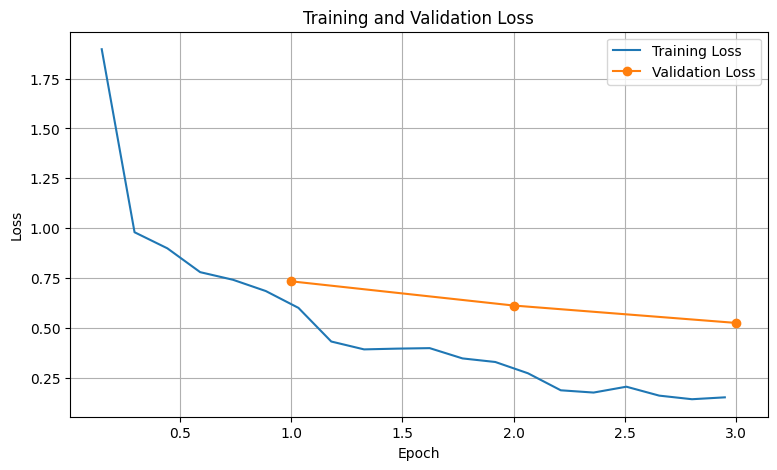

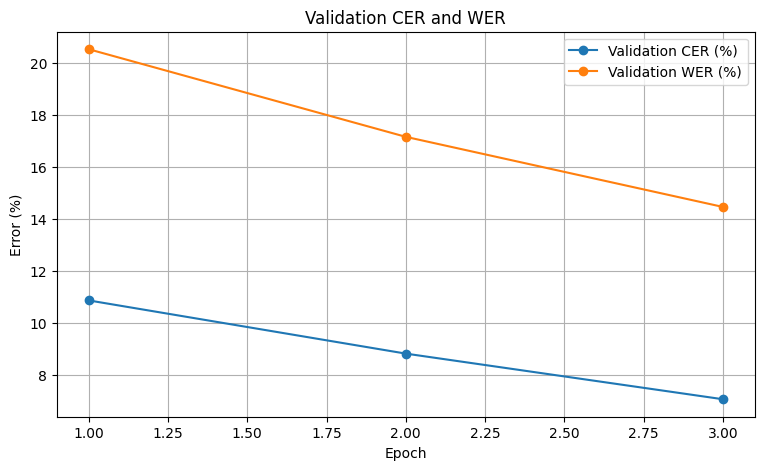

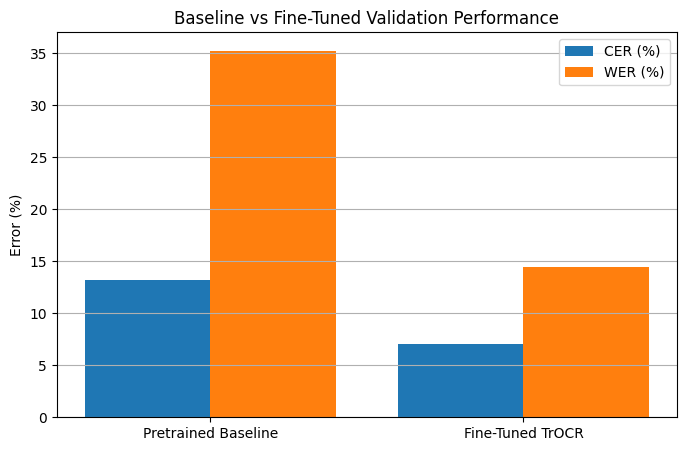


===== SAVED RESULT FILES =====

 /content/drive/MyDrive/TrOCR_Assignment_02/results
- baseline_results.csv
- final_metrics.csv
- test.csv
- test_predictions.csv
- train.csv
- training_history.json
- validation.csv

 /content/drive/MyDrive/TrOCR_Assignment_02/plots
- baseline_comparison.png
- dataset_samples.png
- loss_curve.png
- validation_metrics.png


In [ ]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

# 1. Save final metrics
metrics_df = pd.DataFrame([
    {
        "Model": "Pretrained Baseline",
        "Dataset": "Validation",
        "CER": 0.1320,
        "WER": 0.3524
    },
    {
        "Model": "Fine-Tuned TrOCR",
        "Dataset": "Validation",
        "CER": 0.0707279448,
        "WER": 0.144601
    },
    {
        "Model": "Fine-Tuned TrOCR",
        "Dataset": "Test",
        "CER": test_cer,
        "WER": test_wer
    }
])

metrics_df.to_csv(
    os.path.join(RESULTS_DIR, "final_metrics.csv"),
    index=False
)

print("===== FINAL METRICS =====")
print(metrics_df.to_string(index=False))


# 2. Extract training history
history = trainer_corrected.state.log_history

training_losses = [
    item for item in history
    if "loss" in item and "eval_loss" not in item
]

validation_history = [
    item for item in history
    if "eval_loss" in item
]

# 3. Training and validation loss graph
plt.figure(figsize=(9, 5))

plt.plot(
    [x["epoch"] for x in training_losses],
    [x["loss"] for x in training_losses],
    label="Training Loss"
)

plt.plot(
    [x["epoch"] for x in validation_history],
    [x["eval_loss"] for x in validation_history],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(PLOTS_DIR, "loss_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 4. Validation CER and WER graph
plt.figure(figsize=(9, 5))

plt.plot(
    [x["epoch"] for x in validation_history],
    [x["eval_cer"] * 100 for x in validation_history],
    marker="o",
    label="Validation CER (%)"
)

plt.plot(
    [x["epoch"] for x in validation_history],
    [x["eval_wer"] * 100 for x in validation_history],
    marker="o",
    label="Validation WER (%)"
)

plt.xlabel("Epoch")
plt.ylabel("Error (%)")
plt.title("Validation CER and WER")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(PLOTS_DIR, "validation_metrics.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 5. Baseline vs fine-tuned validation comparison
comparison = metrics_df[
    metrics_df["Dataset"] == "Validation"
]

plt.figure(figsize=(8, 5))

x = range(len(comparison))

plt.bar(
    [i - 0.2 for i in x],
    comparison["CER"] * 100,
    width=0.4,
    label="CER (%)"
)

plt.bar(
    [i + 0.2 for i in x],
    comparison["WER"] * 100,
    width=0.4,
    label="WER (%)"
)

plt.xticks(
    list(x),
    comparison["Model"]
)

plt.ylabel("Error (%)")
plt.title("Baseline vs Fine-Tuned Validation Performance")
plt.legend()
plt.grid(axis="y")
plt.savefig(
    os.path.join(PLOTS_DIR, "baseline_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print("\n===== SAVED RESULT FILES =====")

for folder in [RESULTS_DIR, PLOTS_DIR]:
    print("\n", folder)
    for filename in sorted(os.listdir(folder)):
        print("-", filename)

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

RESULTS_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02/results"

print("Folder exists:", os.path.exists(RESULTS_DIR))

if os.path.exists(RESULTS_DIR):
    print("\nFiles found in results folder:")

    for filename in os.listdir(RESULTS_DIR):
        filepath = os.path.join(RESULTS_DIR, filename)

        if os.path.isfile(filepath):
            print(filename, "-", os.path.getsize(filepath), "bytes")
else:
    print("Results folder not found. Google Drive may need to be mounted.")

Folder exists: True

Files found in results folder:
train.csv - 586822 bytes
validation.csv - 165924 bytes
test.csv - 158159 bytes
baseline_results.csv - 101 bytes
training_history.json - 5058 bytes
test_predictions.csv - 135378 bytes
final_metrics.csv - 178 bytes


In [5]:
import os

PROJECT_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02"

print("Project exists:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    print("\nProject folders:")
    for item in os.listdir(PROJECT_DIR):
        print("-", item)

Project exists: True

Project folders:
- dataset
- checkpoints
- results
- plots
- reports
- validation.csv
- train.csv
- test.csv


In [7]:
import os
import zipfile
from google.colab import files

RESULTS_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02/results"

files_to_upload = [
    "baseline_results.csv",
    "final_metrics.csv",
    "training_history.json",
    "test_predictions.csv"
]

zip_path = "/content/github_results.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for filename in files_to_upload:
        filepath = os.path.join(RESULTS_DIR, filename)

        if os.path.exists(filepath):
            zipf.write(filepath, arcname=filename)
            print("Added:", filename)
        else:
            print("MISSING:", filename)

files.download(zip_path)

Added: baseline_results.csv
Added: final_metrics.csv
Added: training_history.json
Added: test_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
import os

PROJECT_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02"

print("Project exists:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    print("\nProject contents:")
    for item in sorted(os.listdir(PROJECT_DIR)):
        print("-", item)
else:
    print("Project folder not found. Check Google Drive mounting.")

Project exists: True

Project contents:
- checkpoints
- dataset
- plots
- reports
- results
- test.csv
- train.csv
- validation.csv


In [9]:
import os

RESULTS_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02/results"

print("===== RESULTS FOLDER =====")

for filename in sorted(os.listdir(RESULTS_DIR)):
    filepath = os.path.join(RESULTS_DIR, filename)

    if os.path.isfile(filepath):
        print(f"{filename}  |  {os.path.getsize(filepath)} bytes")

===== RESULTS FOLDER =====
baseline_results.csv  |  101 bytes
final_metrics.csv  |  178 bytes
test.csv  |  158159 bytes
test_predictions.csv  |  135378 bytes
train.csv  |  586822 bytes
training_history.json  |  5058 bytes
validation.csv  |  165924 bytes


In [10]:
import os
import zipfile
from google.colab import files

RESULTS_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02/results"

files_to_upload = [
    "baseline_results.csv",
    "final_metrics.csv",
    "training_history.json",
    "test_predictions.csv"
]

zip_path = "/content/github_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in files_to_upload:
        filepath = os.path.join(RESULTS_DIR, filename)

        if os.path.exists(filepath):
            zipf.write(filepath, arcname=filename)
            print("Added:", filename)

print("\nZIP size:", os.path.getsize(zip_path), "bytes")

# Verify ZIP contents
with zipfile.ZipFile(zip_path, "r") as zipf:
    print("\nVerified ZIP contents:")
    for filename in zipf.namelist():
        print("-", filename)

files.download(zip_path)

Added: baseline_results.csv
Added: final_metrics.csv
Added: training_history.json
Added: test_predictions.csv

ZIP size: 43845 bytes

Verified ZIP contents:
- baseline_results.csv
- final_metrics.csv
- training_history.json
- test_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import os
import zipfile
from google.colab import files

PLOTS_DIR = "/content/drive/MyDrive/TrOCR_Assignment_02/plots"

plots_to_upload = [
    "dataset_samples.png",
    "loss_curve.png",
    "validation_metrics.png",
    "baseline_comparison.png"
]

zip_path = "/content/github_plots.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in plots_to_upload:
        filepath = os.path.join(PLOTS_DIR, filename)

        if os.path.exists(filepath):
            zipf.write(filepath, arcname=filename)
            print("Added:", filename)
        else:
            print("MISSING:", filename)

print("\nZIP size:", os.path.getsize(zip_path), "bytes")

with zipfile.ZipFile(zip_path, "r") as zipf:
    print("\nVerified contents:")
    for filename in zipf.namelist():
        print("-", filename)

files.download(zip_path)

Added: dataset_samples.png
Added: loss_curve.png
Added: validation_metrics.png
Added: baseline_comparison.png

ZIP size: 1062780 bytes

Verified contents:
- dataset_samples.png
- loss_curve.png
- validation_metrics.png
- baseline_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>